# Cellohood Analyses - DLPFC

In this notebook we will reproduce results for the analysis of DLPFC dataset.

## Data Preparation

Download Cellohood artifacts from zenodo: #TODO. Then set:


- `DATA_PATH` - path to a full SCVI transformed `dlpfc_scvi.csv` file,


In [10]:
import pandas
import joblib

from ccs import ccs
import cellohood


DATA_PATH = '/raid/immucan/immuw/image_analysis/analysis/UW/packages/IMMUW/scripts/dlpfc_scvi.csv'
data_df = pandas.read_csv(DATA_PATH)


MARKER_COL_NAMES = [
    'SCVI5:0',
    'SCVI5:1',
    'SCVI5:2',
    'SCVI5:3',
    'SCVI5:4',
]


DISTANCE_THRESHOLD = 5.
POS_COL_NAMES = ['pos_x', 'pos_y']
IMAGE_ID_COLUMN = 'sample'
SAMPLE_COL_NAME = 'sample'

TRAIN_MODEL = False
SAVING_PATH = f'/raid/immucan/immuw/cellohood_artifacts/DLPFC/DLPFC_CELLOHOOD_MODEL/'

TRAIN_LATENT_DIRECTIONS = False
LD_SAVING_PATH = 'dlpfc_ld.pickle'

FINAL_DF_SAVING_PATH = 'final_dlpfc.csv'

First step in the data preprocessing is to transform a cell df to a `BagCelloDf` object. This methods runs the hierarchical clustering cells into bags using `DISTANCE_THRESHOLD` as a threshold. It later assigns each cell its bag id (by default `cellohood_neighborhood_cluster`). The object contains:
- `cell_df` - a transformed cell data frame with bag assignment,
- `image_id_column`- check the description of `IMAGE_ID_COLUMN` above,
- `pos_col_names` - check the description of `POS_COL_NAMES` above,
- `distance_threshold` - check the description of `DISTANCE_THRESHOLD` above,
- `marker_col_names` - check the `MARKER_COL_NAMES` above,
- `cellohood_neighborhood_cluster_colname` - in this column an id of a cell's bag is stored (by default `cellohood_neighborhood_cluster`.
        

In [11]:
bag_cello_df = cellohood.transform_df_to_bag_cello_df(
    df_=data_df,
    image_id_column=IMAGE_ID_COLUMN,
    pos_col_names=POS_COL_NAMES,
    distance_threshold=DISTANCE_THRESHOLD,
    marker_col_names=MARKER_COL_NAMES,
)

(array([6.000e+00, 2.000e+01, 2.490e+02, 3.906e+03, 1.180e+03, 1.808e+03,
        9.320e+02, 7.850e+02, 1.880e+02, 2.000e+00]),
 array([ 1. ,  1.9,  2.8,  3.7,  4.6,  5.5,  6.4,  7.3,  8.2,  9.1, 10. ]),
 <BarContainer object of 10 artists>)

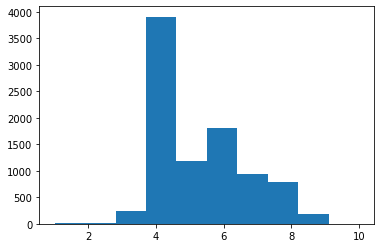

In [12]:
import matplotlib.pyplot as plt

plt.hist(bag_cello_df.cell_df.groupby('cellohood_neighborhood_cluster').size())

If one wants to apply a popular `arcsinh(x / 5.)` transform - there is a function for that:

In [13]:
#_ = cellohood.apply_arcsinh_to_bag_cello_df(bag_cello_df, inplace=True)

Now - it's time for train / test split of the `bag_cello_df`. The code below produces two `BagCelloDf`s - train and test ones. In case, when one wants to train Cellohood without test set (treating it as a sort of cellular neighborhood PCA) - the `split_percentage` should be set to `1.`. In this case, the `test_bag_cello_df` is set to `None`.

**NOTE:** this tests are splitted by samples - so that separate samples are in the train and test sets.

In [14]:
train_bag_cello_df, test_bag_cello_df = cellohood.split_bag_cello_df_by(
    bag_cello_df,
    by=SAMPLE_COL_NAME,
    split_percentage=1.,
)

It is good to standardize data first. The code below uses `standardize_bag_cello_df` function that accepts as its input:
- `train_bag_cello_df`, `test_bag_cello_df` - train and test `BagCelloDfs`,
- `marker_scaler` (default `"standard"`) - a marker scaler. For `"standard"` value it uses Standard Scaler, for `"min-max"` it uses MinMaxScaler, `None` uses Identity Scaler. One may also pass any object with `transform` method that will transform cell marker expressions,
- `pca_dimensions` (default `0`) - number of PCA dimensions used for the analysis. If it is set to `0` no PCA transformation is applied,
- `inplace` (default `False`) - if standarization should be performed in place,
- `fit_marker_scaler` - in case when one passes it's own scaler, this indicates if it will be fitted or not. If set to `True` a passed scaler object should have a `fit` method.

It fits `marker_scaler` on the `train_bag_cello_df`, and applies it to the `test_bag_cello_df` (it automatically covers if `test_bag_cello_df` is `None`). It outputs a `StandardizedBagCelloDfs` `namedtuple` containing:

- `train_cello_df`, `test_cello_df`, `BagCelloDf` objects with scaled `cell_df`s,
- `marker_scaler` - scaler instance,
- `marker_col_names` - names of marker columns,
- `output_size` - size of the single cell vectors (`pca_dimensions` if PCA was applied, `len(marker_col_names)` otherwise).

In [15]:
standardized_cello_dfs = cellohood.standardize_bag_cello_df(
    train_bag_cello_df=train_bag_cello_df, 
    test_bag_cello_df=test_bag_cello_df,
    marker_col_names=MARKER_COL_NAMES,
)

Now, it's time to train `Cellohood`. `cellohood.train` method accepts as its input:


- `standardized_cello_dfs` - a `StandardizedBagCelloDfs` object that `Cellohood` will be trained on,
- `batch_size: int = 512` - a batch size used in the training,
- `epoch_nb: int = 1000` a number of epochs,
- `optimizer_lr: float = 0.0001` - learning rate used by `ADAM` optimizer,
- `optimizer_clipnorm: float = 1.0` - a clip norm for optimizer,
- `use_cuda: bool = True` - if model should be trained on `GPU`,
- `layer_size: int = 128` - a size of the transformer layer sizes for both encoder and decoder,
- `intermediate_layer_size: int = 256` - a size of a hidden transformer later,
- `latent_size: int = 64` - size of a `Cellohood` latent,
- `tensorboard_path: Optional[str] = None` - a log path to optional TensorBoard callback.

This method outputs `CellohoodModel` `namedtuple` with the following fields:
- `model` - an instance of a `Keras` `Cellohood` model,
- `history` - `Keras` training history,
- `marker_scaler` - scaler used in training,
- `marker_col_names` - names of marker used,
- `output_size` output size of a model,
- `max_neighborhood_size` - a maximal bag size used by the model.

In [16]:
if TRAIN_MODEL:
    cello_train_result = cellohood.train(
        standardized_cello_dfs=standardized_cello_dfs,
        epoch_nb=100,
        use_cuda=True,
        #batch_size=256,
    )

once we have a model, we can serialize its result using `cellohood.save_cello_train_result` function. Deserialization is performed by `cellohood.load_cello_train_result`:

In [17]:
import os

#os.environ['CUDA_VISIBLE_DEVICES'] = ''

if TRAIN_MODEL:
    cellohood.save_cello_train_result(cello_train_result, SAVING_PATH)
else:
    cello_train_result = cellohood.load_cello_train_result(SAVING_PATH)

{'output_size': 5, 'max_neighborhood_size': 10, 'latent_size': 64, 'layer_size': 128, 'intermediate_layer_size': 256}


2026-04-16 10:31:02.214792: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-04-16 10:31:02.215521: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-04-16 10:31:02.216182: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-04-16 10:31:02.216868: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2026-04-16 10:31:02.222590: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from S

2026-04-16 10:31:06.441859: I tensorflow/stream_executor/cuda/cuda_dnn.cc:366] Loaded cuDNN version 8201


Now - we are ready to obtain the model results. In order to run prediction of a `Cellohood` model on the `BagCelloDf`, one may use `cellohood.run_prediction_on_cell_df`. Note however, that the data that this model is used on should not be scaled, as the scaling of the data is performed using scaler used during the train. That's why in the code below we use non-scaled `BagCelloDf`:

In [18]:
cello_prediction = cellohood.run_prediction_on_cello_df(
    cello_train_result,
    bag_cello_df,
)

/raid/immucan/immuw/cellohood-final/lib/python3.8/site-packages/keras/engine/training_v1.py:2079: UserWarning: `Model.state_updates` will be removed in a future version. This property should not be used in TensorFlow 2.0, as `updates` are applied automatically.
  updates=self.state_updates,


It outputs `CelloPrediction` `namedtuple` with fields:
- `cell_predictions` - with dataframe of Cellohood cell representations, together with image and position information,
- `bag_predictions` - with dataframe of Cellohood bag representations, together with image and position information,
- `cello_columns` - with set of column names storing the Cellohood representations,
- `cellohood_neighborhood_cluster_colname` - column with the cellohood bag index,
- `image_id_column` - column with information about the image id,
- `pos_col_names` - positional columns.

As we use a set of disjoint bags in the training, we decided to compensate for the effect that disjoint tissue cutting might have on results - by spatially smoothing the results. Here - the value for each cell is spatially smoothed across all cells within a `distance_threshold`. In our experiments we set it to `DISTANCE_THRESHOLD` that is the same threshold as we used in original tissue cutting. Note - that as this process might be time / memory consuming we implemented multiprocess setup which uses `cache_path` folder to cache multiprocess result. Be default, for safety reasons, we implemented the assertion that this folder does not exist, so make sure that you use unused folder.

In [19]:
import importlib
from cellohood.data_processing import spatial_directions
from cellohood.training import training

importlib.reload(cellohood)
importlib.reload(spatial_directions)
importlib.reload(training)

<module 'cellohood.training.training' from '/raid/immucan/immuw/cellohood/cellohood/training/training.py'>

In [20]:
!rm -r new_cache

rm: cannot remove 'new_cache': No such file or directory


In [21]:
smoothed_df_result = cellohood.smooth_cellohood_prediction(
    cello_prediction,
    distance_threshold=DISTANCE_THRESHOLD,
    cache_path='new_cache',
)

In [22]:
from sklearn.decomposition import PCA


decomposer = PCA()
decomposed = decomposer.fit_transform(smoothed_df_result.cell_predictions[smoothed_df_result.cello_columns].values)

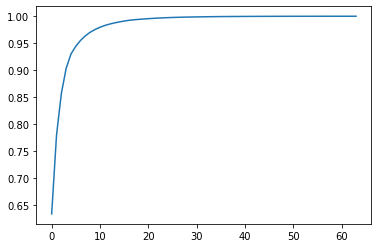

In [23]:
plt.plot(decomposer.explained_variance_ratio_.cumsum())

In [33]:
import numpy


numpy.argmin(numpy.abs(decomposer.explained_variance_ratio_.cumsum() - 0.75))

1

In [24]:
layers_ = sorted(list(set(bag_cello_df.cell_df['layer'])))

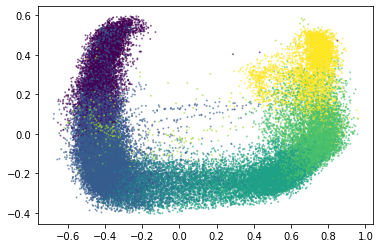

In [25]:
plt.scatter(
    decomposed[:, 0],
    decomposed[:, 1],
    c=bag_cello_df.cell_df['layer'].apply(lambda x: layers_.index(x)),
    alpha=0.5,
    s=1,
)

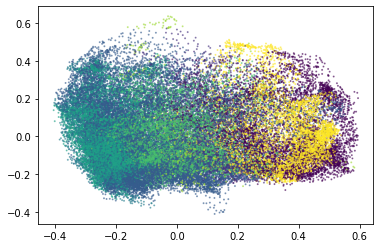

In [26]:
plt.scatter(
    decomposed[:, 1],
    decomposed[:, 2],
    c=bag_cello_df.cell_df['layer'].apply(lambda x: layers_.index(x)),
    alpha=0.5,
    s=1,
)

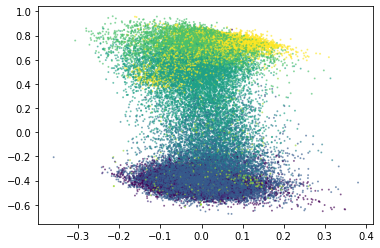

In [27]:
plt.scatter(
    decomposed[:, 5],
    decomposed[:, 0],
    c=bag_cello_df.cell_df['layer'].apply(lambda x: layers_.index(x)),
    alpha=0.5,
    s=1,
)

In [28]:
samples_ = list(set(bag_cello_df.cell_df['sample']))

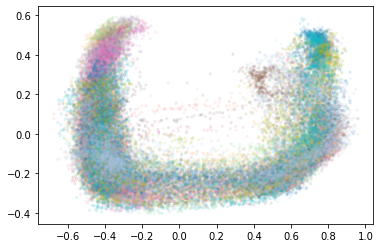

In [29]:
plt.scatter(
    decomposed[:, 0],
    decomposed[:, 1],
    c=bag_cello_df.cell_df['sample'].apply(lambda x: samples_.index(x)),
    alpha=0.1,
    s=5,
    cmap='tab20',
)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10/10 [00:10<00:00,  1.08s/it]


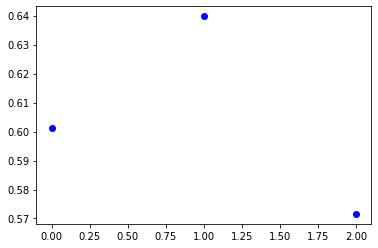

In [22]:
from collections import defaultdict
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_mutual_info_score, adjusted_rand_score


from scipy.stats import ttest_rel
import numpy
import tqdm



NB_OF_RUNS = 10


# From Cellcharter paper
TEST_SAMPLES = [
    151507,
    151672,
    151673
]

NON_TEST_SAMPLES = [
    sample 
    for sample in sorted(bag_cello_df.cell_df['sample'].unique())
    if sample not in TEST_SAMPLES
]


current_random_seed = 42
sample_to_test_aris_standard = defaultdict(list)
variables = [0, 1]

test_cello_df = bag_cello_df.cell_df[bag_cello_df.cell_df['sample'].apply(lambda x: x in TEST_SAMPLES)]


for _ in tqdm.tqdm(range(NB_OF_RUNS)):
    # Fitting the model
    current_clusterer = GaussianMixture(7, random_state=current_random_seed)
    current_random_seed += 1
    
    
    # Running prediction on samples
    for sample in sorted(bag_cello_df.cell_df['sample'].unique()):
        if sample in NON_TEST_SAMPLES:
            continue
        sample_all_df = bag_cello_df.cell_df[bag_cello_df.cell_df['sample'] == sample]
        sample_non_unk_df = sample_all_df[sample_all_df['layer'] != 'UNK']
        
        sample_ld = training_ld[test_cello_df['sample'] == sample][:, variables]
        sample_ld = sample_ld[(sample_all_df['layer'] != 'UNK').values]
        sample_gt = sample_non_unk_df['layer'].apply(lambda x: layers_.index(x))
        
        sample_preds = current_clusterer.predict(sample_ld)
        current_ari = adjusted_rand_score(sample_preds, sample_gt)
        
        sample_to_test_aris_standard[sample].append(current_ari)
        
        
test_means_standard = []
for sample_id, sample in enumerate(sorted(sample_to_test_aris_standard)):
    test_means_standard.append(numpy.mean(sample_to_test_aris_standard[sample]))
plt.scatter(
    list(range(len(test_means_standard))),
    test_means_standard,
    c='b',
    label='Cello'
)

In [23]:
current_random_seed = 42
sample_to_test_aris_coarse = defaultdict(list)
variables = [0]


for _ in tqdm.tqdm(range(NB_OF_RUNS)):
    # Fitting the model
    current_clusterer = GaussianMixture(7, random_state=current_random_seed)
    current_random_seed += 1
    training_ld = decomposed[
        bag_cello_df.cell_df['sample'].apply(lambda x: x in TEST_SAMPLES),
    ][:, variables] 
    current_clusterer.fit(training_ld)
    
    # Running prediction on samples
    for sample in sorted(bag_cello_df.cell_df['sample'].unique()):
        if sample in NON_TEST_SAMPLES:
            continue
        sample_all_df = bag_cello_df.cell_df[bag_cello_df.cell_df['sample'] == sample]
        sample_non_unk_df = sample_all_df[sample_all_df['layer'] != 'UNK']
        
        sample_ld = training_ld[test_cello_df['sample'] == sample][:, variables]
        sample_ld = sample_ld[(sample_all_df['layer'] != 'UNK').values]
        sample_gt = sample_non_unk_df['layer'].apply(lambda x: layers_.index(x))
        
        sample_preds = current_clusterer.predict(sample_ld)
        current_ari = adjusted_rand_score(sample_preds, sample_gt)
        
        sample_to_test_aris_coarse[sample].append(current_ari)
        
test_means_coarse = []
for sample_id, sample in enumerate(sorted(sample_to_test_aris_coarse)):
    test_means_coarse.append(numpy.mean(sample_to_test_aris_coarse[sample]))

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10/10 [00:09<00:00,  1.03it/s]


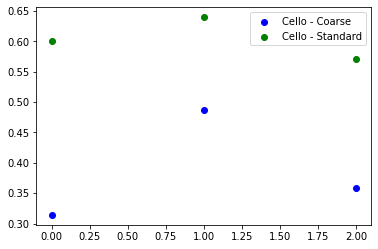

In [24]:
plt.scatter(
    list(range(len(test_means_coarse))),
    test_means_coarse,
    c='b',
    label='Cello - Coarse'
)
plt.scatter(
    list(range(len(test_means_standard))),
    test_means_standard,
    c='g',
    label='Cello - Standard'
)

plt.legend()

In [25]:
numpy.median(test_means_standard), numpy.median(test_means_coarse)

(0.6011235415451084, 0.35894191909332407)

In [26]:
SAMPLES = {#'151507': 7, 
           '151508': 7, 
           '151509': 7, 
           '151510': 7, 
           '151669': 5, 
           '151670': 5, 
           '151671': 5, 
           #'151672': 5, 
           #'151673': 7, 
           '151674': 7, 
           '151675': 7, 
           '151676': 7
}

After smoothin it's worth to delete `cache`:

  0%|                                                                                                                                                                                | 0/10 [00:00<?, ?it/s]

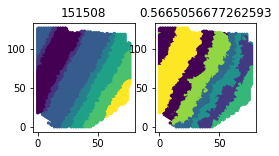

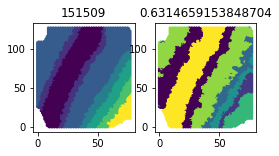

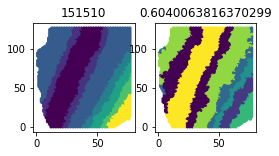

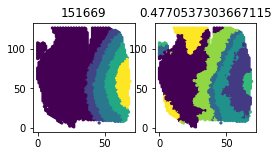

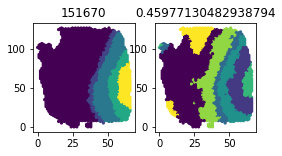

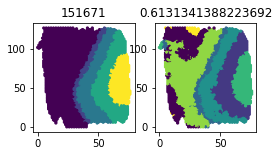

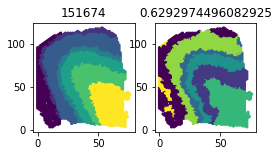

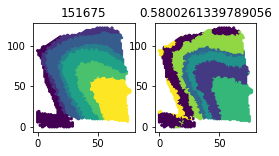

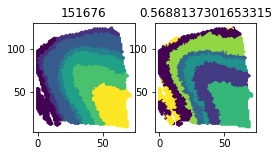

 10%|████████████████▊                                                                                                                                                       | 1/10 [00:05<00:49,  5.52s/it]

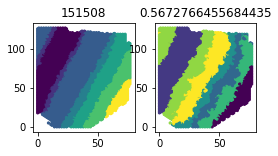

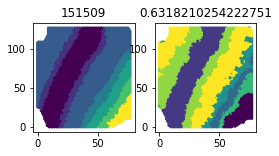

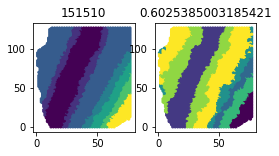

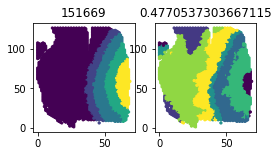

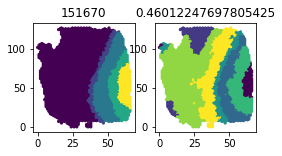

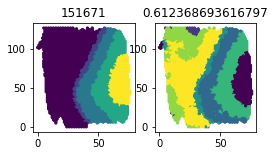

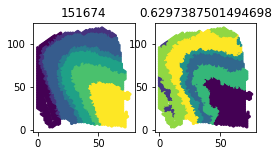

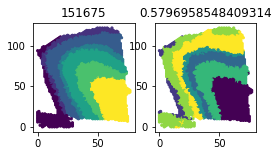

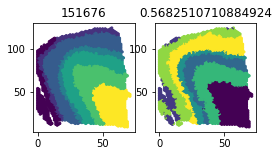

 20%|█████████████████████████████████▌                                                                                                                                      | 2/10 [00:10<00:39,  4.93s/it]

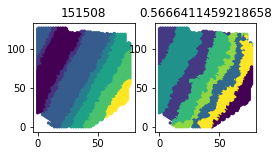

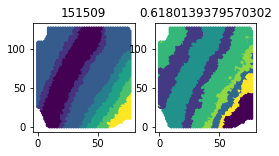

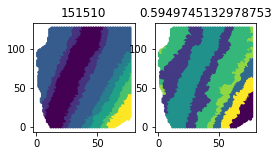

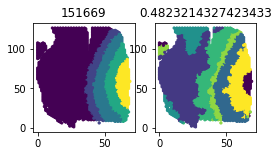

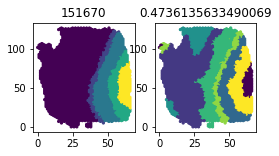

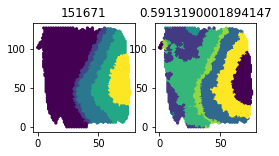

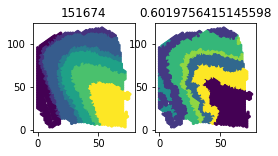

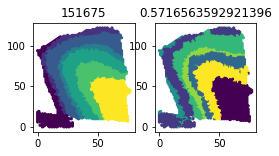

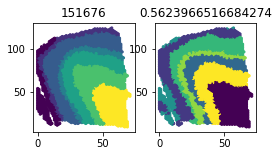

 30%|██████████████████████████████████████████████████▍                                                                                                                     | 3/10 [00:13<00:30,  4.41s/it]

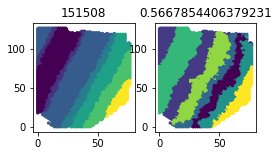

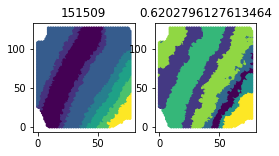

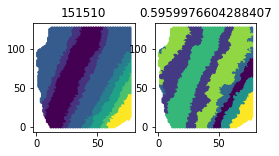

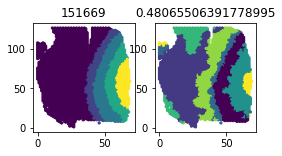

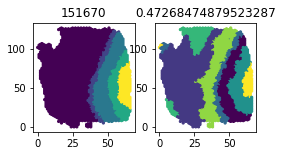

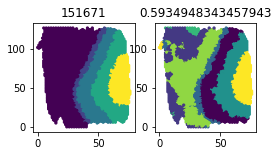

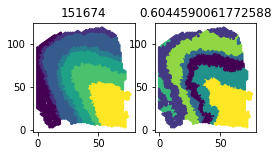

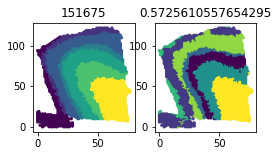

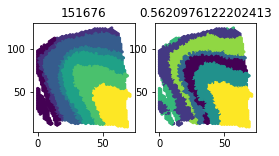

 40%|███████████████████████████████████████████████████████████████████▏                                                                                                    | 4/10 [00:17<00:25,  4.23s/it]

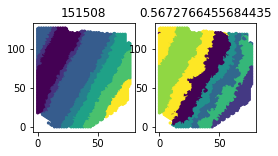

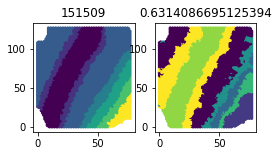

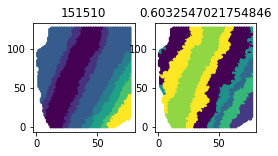

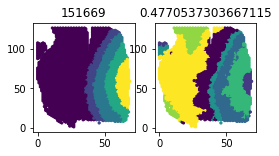

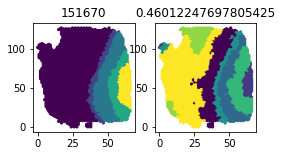

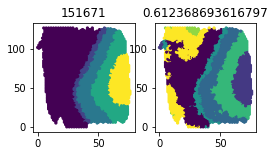

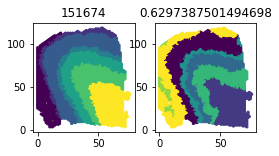

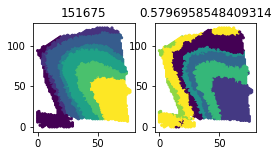

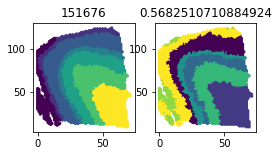

 50%|████████████████████████████████████████████████████████████████████████████████████                                                                                    | 5/10 [00:24<00:25,  5.08s/it]

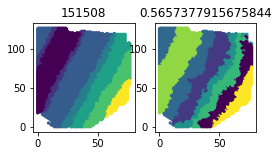

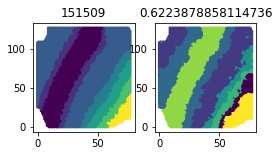

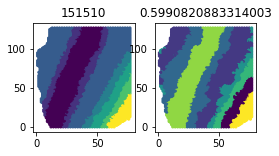

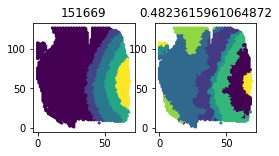

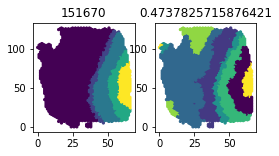

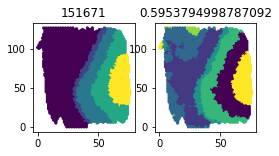

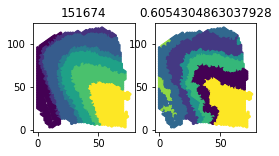

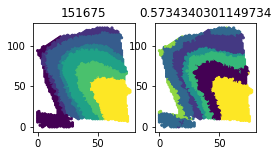

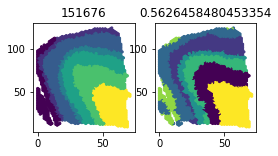

 60%|████████████████████████████████████████████████████████████████████████████████████████████████████▊                                                                   | 6/10 [00:28<00:19,  4.76s/it]

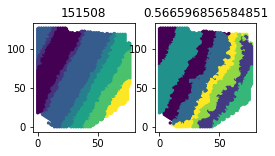

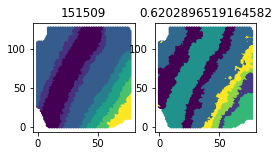

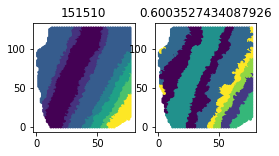

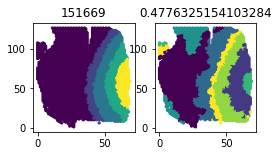

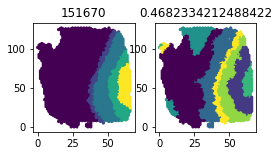

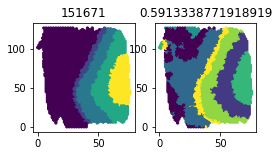

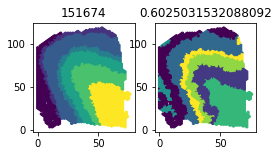

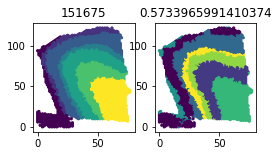

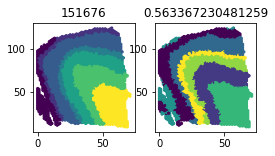

 70%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▌                                                  | 7/10 [00:31<00:12,  4.23s/it]

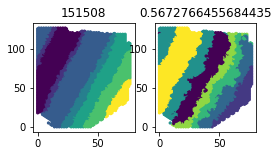

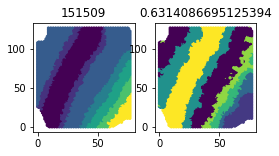

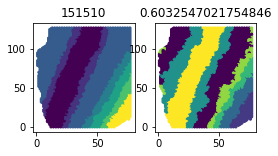

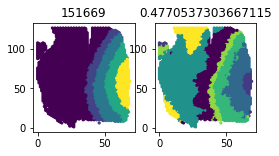

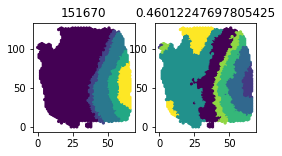

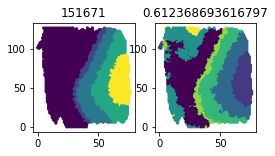

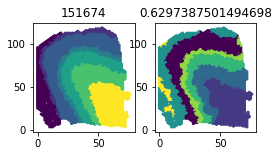

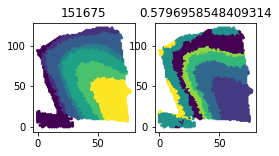

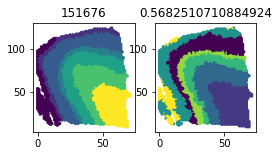

 80%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▍                                 | 8/10 [00:37<00:09,  4.77s/it]

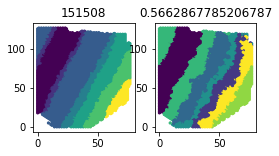

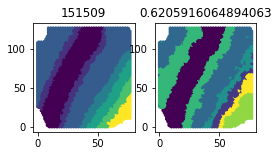

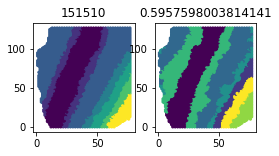

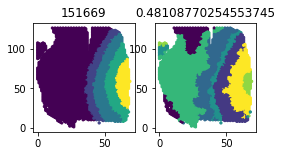

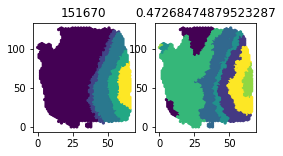

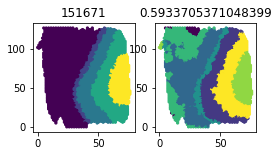

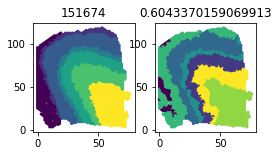

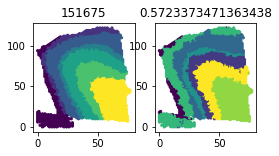

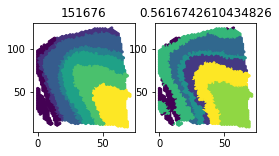

 90%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▏                | 9/10 [00:41<00:04,  4.65s/it]

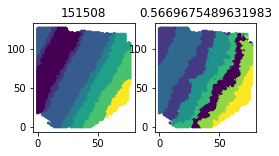

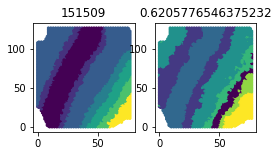

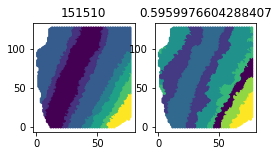

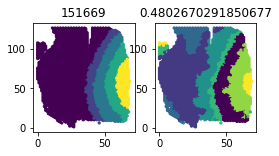

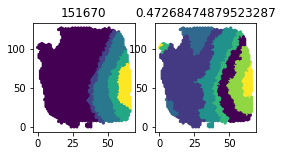

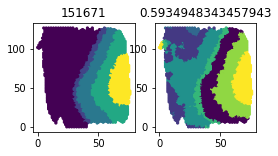

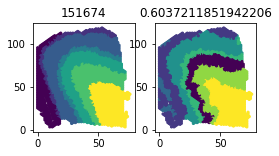

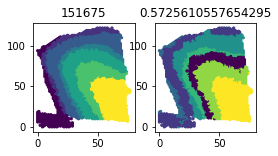

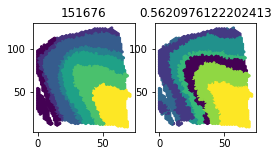

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10/10 [00:47<00:00,  4.78s/it]


In [27]:
from collections import defaultdict
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_mutual_info_score, adjusted_rand_score


from scipy.stats import ttest_rel
import numpy
import tqdm



NB_OF_RUNS = 10


# From Cellcharter paper
TEST_SAMPLES = [
    151507,
    151672,
    151673
]

NON_TEST_SAMPLES = [
    sample 
    for sample in sorted(bag_cello_df.cell_df['sample'].unique())
    if sample not in TEST_SAMPLES
]


current_random_seed = 42
sample_to_aris = defaultdict(list)
clusterers = []
variables = [0, 1]

train_cello_df = bag_cello_df.cell_df[bag_cello_df.cell_df['sample'].apply(lambda x: x not in TEST_SAMPLES)]


for _ in tqdm.tqdm(range(NB_OF_RUNS)):
    # Fitting the model
    current_clusterer = GaussianMixture(7, random_state=current_random_seed)
    current_random_seed += 1
    training_ld = decomposed[
        bag_cello_df.cell_df['sample'].apply(lambda x: x not in TEST_SAMPLES),
    ][:, variables]# / decomposer.explained_variance_ratio_[:2]
    current_clusterer.fit(training_ld)
    clusterers.append(current_clusterer)
    
    # Running prediction on samples
    for sample in sorted(bag_cello_df.cell_df['sample'].unique()):
        if sample in TEST_SAMPLES:
            continue
        sample_all_df = bag_cello_df.cell_df[bag_cello_df.cell_df['sample'] == sample]
        sample_non_unk_df = sample_all_df[sample_all_df['layer'] != 'UNK']
        
        sample_ld = training_ld[train_cello_df['sample'] == sample][:, variables]
        sample_ld = sample_ld[(sample_all_df['layer'] != 'UNK').values]
        sample_gt = sample_non_unk_df['layer'].apply(lambda x: layers_.index(x))
        
        sample_preds = current_clusterer.predict(sample_ld)
        current_ari = adjusted_rand_score(sample_preds, sample_gt)
        
        sample_to_aris[sample].append(current_ari)
        
        plt.figure(figsize=(4, 2))
        plt.subplot(1, 2, 1)
        plt.scatter(
            sample_non_unk_df.pos_x,
            sample_non_unk_df.pos_y,
            c=sample_non_unk_df['layer'].apply(lambda x: layers_.index(x)),
            s=5,
        )
        plt.title(sample)
        plt.subplot(1, 2, 2)
        plt.scatter(
            sample_non_unk_df.pos_x,
            sample_non_unk_df.pos_y,
            c=sample_preds,
            s=5,
        )
        plt.title(current_ari)
        plt.show()

In [28]:
cellcharter = pandas.read_csv('/raid/immucan/immuw/tumorhood/tumorhood_bc/notebooks/ARI_CellCharter_hvgs5000_nlatent5_nhoodlayers4_gpu_joint.csv')
cellcharter_means = cellcharter.values[:, 1:].mean(axis=1)

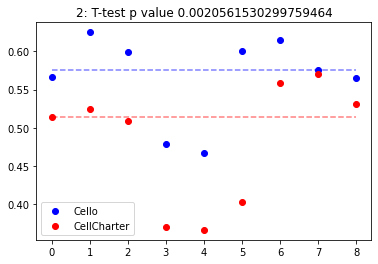

In [29]:
train_means = []
for sample_id, sample in enumerate(sorted(sample_to_aris)):
    train_means.append(numpy.mean(sample_to_aris[sample]))
plt.scatter(
    list(range(9)),
    train_means,
    c='b',
    label='Cello'
)
ch_median = numpy.median(train_means)
cch_median = numpy.median(numpy.median(cellcharter.values[:, 1:].mean(axis=1)))
plt.plot([0, 8], [ch_median, ch_median],  '--', c='b', alpha=0.5)
plt.scatter(
        list(range(9)),
        cellcharter.values[:, 1:].mean(axis=1),
        c='r',
        label='CellCharter',
    )
ttest = ttest_rel(train_means, cellcharter.values[:, 1:].mean(axis=1)).pvalue
plt.title(f'{2}: T-test p value {ttest}')
plt.plot([0, 8], [cch_median, cch_median], '--', c='r', alpha=0.5)
plt.legend()

In [30]:
sample_aris_df = pandas.DataFrame(
    sample_to_aris
)

In [31]:
best_clusterer = clusterers[sample_aris_df.mean(axis=1).argmax()]

In [32]:
best_clusterer

GaussianMixture(n_components=7, random_state=42)

In [33]:
predictions = best_clusterer.predict(decomposed[:, variables])

In [34]:
true_layers = ['L1', 'L2', 'L3', 'L4', 'L5', 'L6', 'WM']

In [35]:
prediction_to_layer = numpy.zeros((7, 7))

for pred, gt in zip(predictions, bag_cello_df.cell_df['layer']):
    if gt == 'UNK':
        continue
    prediction_to_layer[true_layers.index(gt), pred] += 1

In [36]:
set(predictions)

{0, 1, 2, 3, 4, 5, 6}

In [37]:
prediction_to_layer_pred_normed = prediction_to_layer / prediction_to_layer.sum(axis=0) * 100

In [38]:
prediction_to_layer_df = pandas.DataFrame(
    prediction_to_layer_pred_normed,
    index=true_layers,
)

In [39]:
prediction_to_layer_df

,0,1,2,3,4,5,6
L1,10.041675,0.000000,0.000000,0.000000,0.062893,0.063880,83.706443
L2,24.975193,0.000000,0.000000,0.000000,0.000000,0.730060,5.080786
L3,64.973209,0.000000,14.160700,0.000000,0.461216,90.408834,11.212770
L4,0.009923,0.000000,61.177407,4.787604,0.000000,8.797226,0.000000
L5,0.000000,17.944986,24.635375,89.397632,0.062893,0.000000,0.000000
L6,0.000000,74.632513,0.026518,5.814763,15.471698,0.000000,0.000000
WM,0.000000,7.422500,0.000000,0.000000,83.941300,0.000000,0.000000


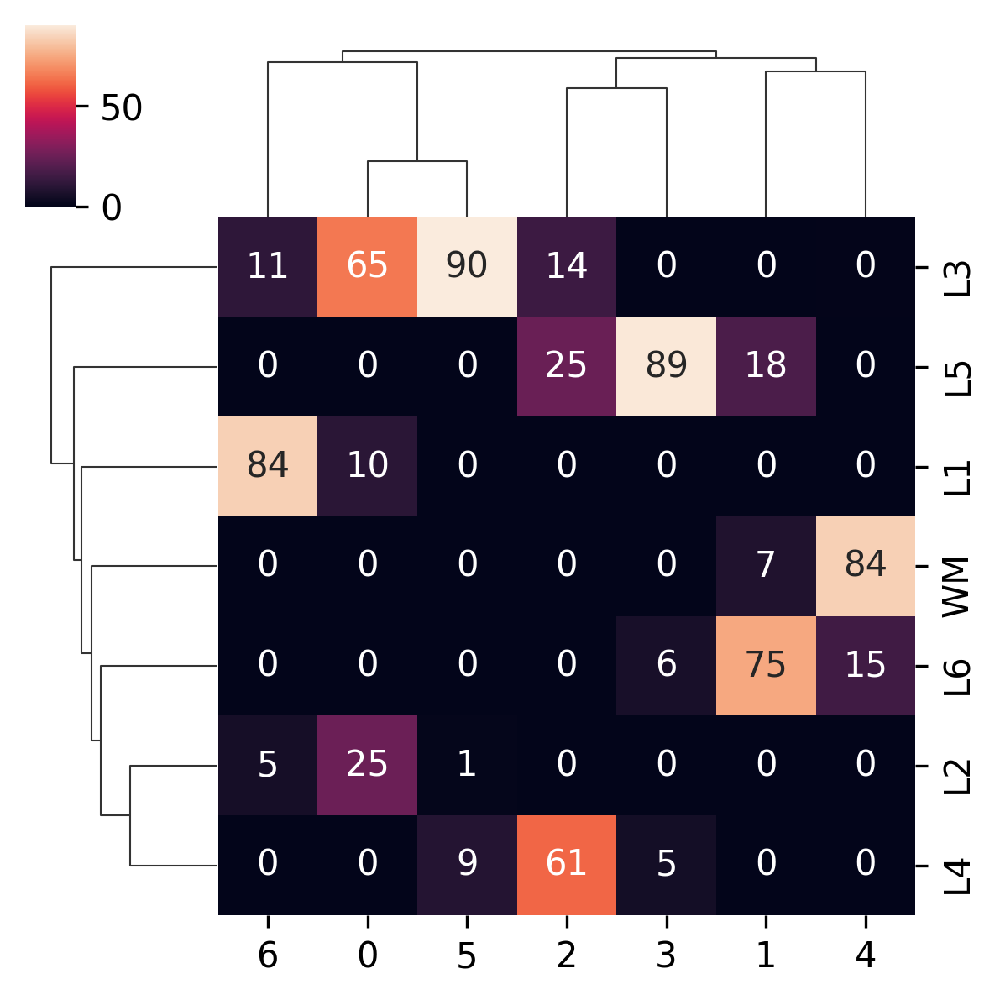

In [40]:
import seaborn as sns

pred_normed_cm = sns.clustermap(prediction_to_layer_df, annot=True, fmt='.0f', figsize=(4, 4))
pred_normed_cm.fig.set_dpi(300)

In [41]:
pred_to_layer_assignment = {
    6: 'L1',
    1: 'L6',
    3: 'L5',
    2: 'L4',
    0: 'L2',
    5: 'L3',
    4: 'WM',
}

In [42]:
import seaborn as sns
import matplotlib


# Plotting
PLOTTING_DPI = 300
sns.set_context("paper", rc={"font.size": 6, "axes.titlesize":6,"axes.labelsize":6})  
plt.rcParams['legend.title_fontsize'] = 6
plt.rcParams['legend.fontsize'] = 6

matplotlib.font_manager.fontManager.addfont('/raid/immucan/immuw/Arial.ttf')  # if you need to add the font file
plt.rcParams['font.family'] = 'Arial'

## Supplementary: All Samples

In [43]:
SAMPLES_IN_ORDER = [
    151508,
    151509,
    151510,
    151507,
    151669,
    151670,
    151671,
    151672,
    151674,
    151675,
    151676,
    151673
]

SAMPLES_IN_PLOT_ORDER = SAMPLES_IN_ORDER[::4] + SAMPLES_IN_ORDER[1::4] + SAMPLES_IN_ORDER[2::4] + SAMPLES_IN_ORDER[3::4]

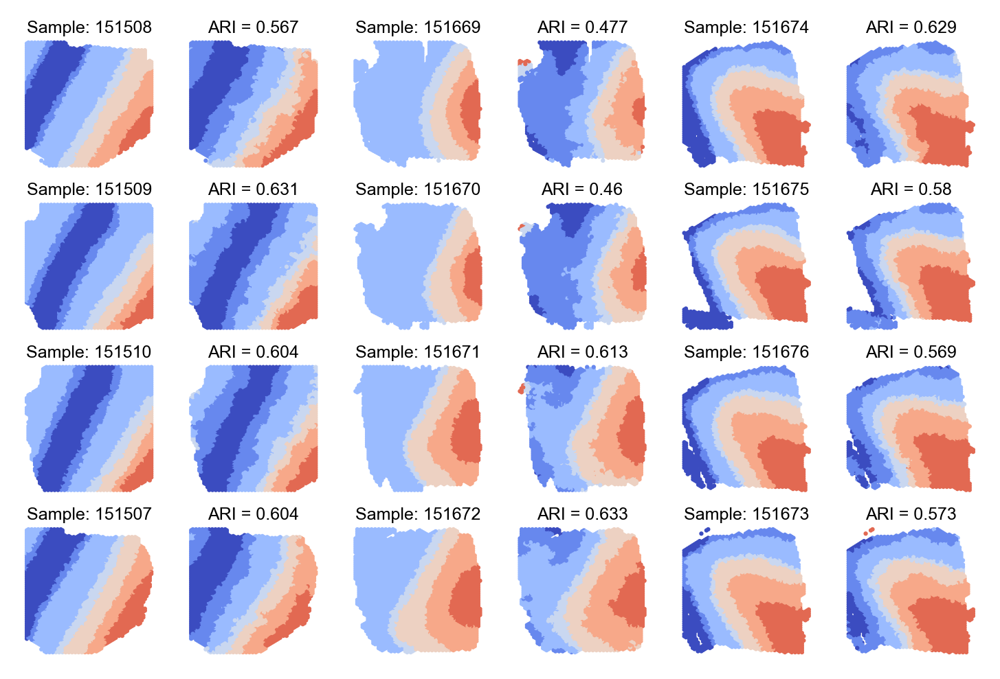

In [44]:
plt.figure(figsize=(6, 4), dpi=300)


for sample_id, sample in enumerate(SAMPLES_IN_PLOT_ORDER):
    sample_all_df = bag_cello_df.cell_df[bag_cello_df.cell_df['sample'] == sample]
    sample_non_unk_df = sample_all_df[sample_all_df['layer'] != 'UNK']

    sample_ld = decomposed[bag_cello_df.cell_df['sample'] == sample][:, variables]
    sample_ld = sample_ld[(sample_all_df['layer'] != 'UNK').values]
    sample_gt = sample_non_unk_df['layer'].apply(lambda x: layers_.index(x))

    sample_preds = best_clusterer.predict(sample_ld)
    current_ari = adjusted_rand_score(sample_preds, sample_gt)

    sample_to_aris[sample].append(current_ari)

    
    plt.subplot(4, 6, 2 * sample_id + 1)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=sample_non_unk_df['layer'].apply(lambda x: true_layers.index(x)),
        cmap='coolwarm',
        s=0.5,
        vmax=7,
        vmin=0,
    )
    plt.axis('off')
    plt.title(f'Sample: {sample}', pad=0.5, size=6)
    plt.subplot(4, 6, 2 * sample_id + 2)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=[true_layers.index(pred_to_layer_assignment[x]) for x in sample_preds],
        s=0.5,
        cmap='coolwarm',
        vmax=7,
        vmin=0,
    )
    plt.axis('off')
    plt.title(f'ARI = {round(current_ari, 3)}', pad=0.5, size=6)

## Main Figure 2, Panel a

In [45]:
PANEL_A_SAMPLES = [
    151675,
    151671,
    151510,
]

/tmp/ipykernel_3696825/1665939682.py:58: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_3696825/1665939682.py:60: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)
/tmp/ipykernel_3696825/1665939682.py:58: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_3696825/1665939682.py:60: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)
/tmp/ipykernel_3696825/1665939682.py:58: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_3696825/1665939682.py:60: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6

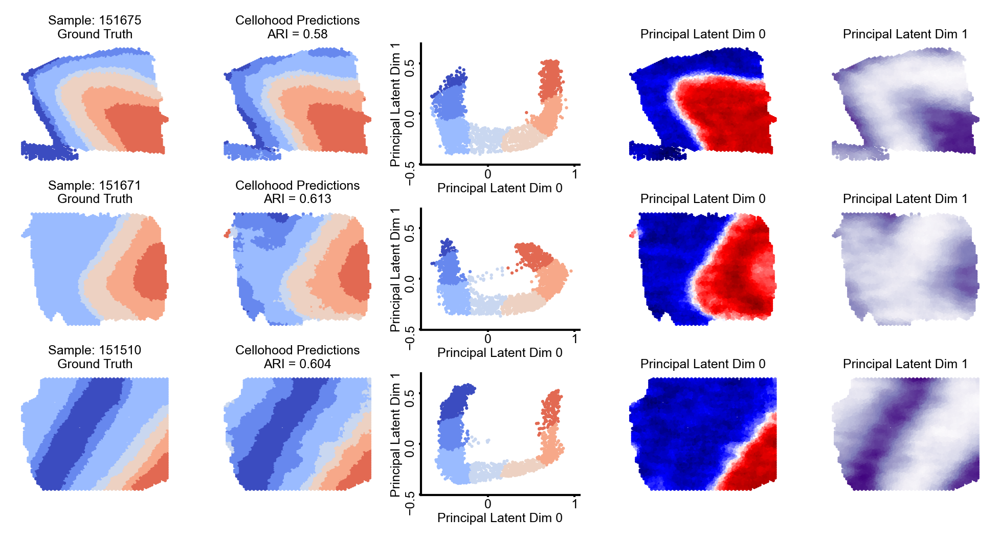

In [46]:
plt.figure(figsize=(6.5, 3.5), dpi=300)


for sample_id, sample in enumerate(PANEL_A_SAMPLES):
    sample_all_df = bag_cello_df.cell_df[bag_cello_df.cell_df['sample'] == sample]
    sample_non_unk_df = sample_all_df[sample_all_df['layer'] != 'UNK']

    sample_ld = decomposed[bag_cello_df.cell_df['sample'] == sample][:, variables]
    sample_ld = sample_ld[(sample_all_df['layer'] != 'UNK').values]
    sample_gt = sample_non_unk_df['layer'].apply(lambda x: layers_.index(x))

    sample_preds = best_clusterer.predict(sample_ld)
    current_ari = adjusted_rand_score(sample_preds, sample_gt)

    sample_to_aris[sample].append(current_ari)

    
    plt.subplot(3, 5, 5 * sample_id + 1)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=sample_non_unk_df['layer'].apply(lambda x: true_layers.index(x)),
        cmap='coolwarm',
        s=0.5,
        vmax=7,
        vmin=0,
    )
    plt.axis('off')
    plt.title(f'Sample: {sample}\nGround Truth', pad=2.5, size=6)
    plt.subplot(3, 5, 5 * sample_id + 2)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=[true_layers.index(pred_to_layer_assignment[x]) for x in sample_preds],
        s=0.5,
        cmap='coolwarm',
        vmax=7,
        vmin=0,
    )
    plt.axis('off')
    plt.title(f'Cellohood Predictions\nARI = {round(current_ari, 3)}', pad=2.5, size=6)
    plt.subplot(3, 5, 5 * sample_id + 3)
    plt.scatter(
        sample_ld[:, 0],
        sample_ld[:, 1],
        c=[true_layers.index(pred_to_layer_assignment[x]) for x in sample_preds],
        s=0.5,
        cmap='coolwarm',
        vmax=7,
        vmin=0,
    )
    plt.xlim([training_ld[:, 0].min() - 0.1, training_ld[:, 0].max() + 0.1])
    plt.ylim([training_ld[:, 1].min() - 0.1, training_ld[:, 1].max() + 0.1])
    ax = plt.gca()
    ax.xaxis.set_tick_params(size=1, pad=1)
    ax.set_xlabel('Principal Latent Dim 0', size=6, labelpad=1)
    ax.set_ylabel('Principal Latent Dim 1', size=6, labelpad=1)
    ax.set_xticklabels(ax.get_xticklabels(), size=6)
    ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
    ax.set_yticklabels(ax.get_yticklabels(), size=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.subplot(3, 5, 5 * sample_id + 4)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=sample_ld[:, 0],
        s=0.5,
        vmin=training_ld[:, 0].min(),
        vmax=training_ld[:, 0].max(),
        cmap='seismic',
    )
    #plt.colorbar()
    plt.axis('off')
    plt.title(f'Principal Latent Dim 0', pad=2.5, size=6)
    plt.subplot(3, 5, 5 * sample_id + 5)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=sample_ld[:, 1],
        s=0.5,
        cmap='Purples',
        vmin=training_ld[:, 1].min(),
        vmax=training_ld[:, 1].max(),
    )
    plt.axis('off')
    plt.title(f'Principal Latent Dim 1', pad=2.5, size=6)
    #plt.colorbar()
    #ax.set_title('Spot Latent Representations', size=6, pad=2.5)
plt.subplots_adjust(hspace=0.25, wspace=0.25)
plt.tight_layout()

## Colorbars:

/tmp/ipykernel_3696825/1169526266.py:13: UserWarning: FixedFormatter should only be used together with FixedLocator
  cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)


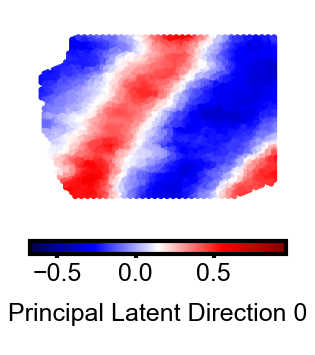

In [47]:
plt.figure(figsize=(1.1, 1.1), dpi=300)
plt.scatter(
    sample_non_unk_df.pos_x,
    sample_non_unk_df.pos_y,
    c=sample_ld[:, 1],
    s=0.5,
    cmap='seismic',
    vmin=training_ld[:, 0].min(),
    vmax=training_ld[:, 0].max(),
)
plt.axis('off')
cbar = plt.colorbar(orientation='horizontal')
cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)
cbar.ax.xaxis.set_tick_params(size=1, pad=1)
cbar.set_label('Principal Latent Direction 0')

/tmp/ipykernel_3696825/3364969604.py:13: UserWarning: FixedFormatter should only be used together with FixedLocator
  cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)


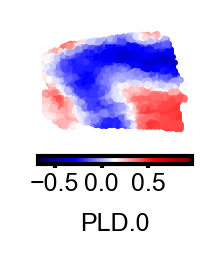

In [167]:
plt.figure(figsize=(0.66, 0.66), dpi=300)
plt.scatter(
    sample_non_unk_df.pos_x,
    sample_non_unk_df.pos_y,
    c=sample_ld[:, 1],
    s=0.5,
    cmap='seismic',
    vmin=training_ld[:, 0].min(),
    vmax=training_ld[:, 0].max(),
)
plt.axis('off')
cbar = plt.colorbar(orientation='horizontal')
cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)
cbar.ax.xaxis.set_tick_params(size=1, pad=1)
cbar.set_label('PLD.0')

/tmp/ipykernel_3696825/1692604597.py:13: UserWarning: FixedFormatter should only be used together with FixedLocator
  cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)


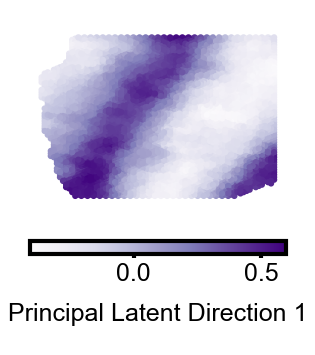

In [48]:
plt.figure(figsize=(1.1, 1.1), dpi=300)
plt.scatter(
    sample_non_unk_df.pos_x,
    sample_non_unk_df.pos_y,
    c=sample_ld[:, 1],
    s=0.5,
    cmap='Purples',
    vmin=training_ld[:, 1].min(),
    vmax=training_ld[:, 1].max(),
)
plt.axis('off')
cbar = plt.colorbar(orientation='horizontal')
cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)
cbar.ax.xaxis.set_tick_params(size=1, pad=1)
cbar.set_label('Principal Latent Direction 1')

/tmp/ipykernel_3696825/284134577.py:13: UserWarning: FixedFormatter should only be used together with FixedLocator
  cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)


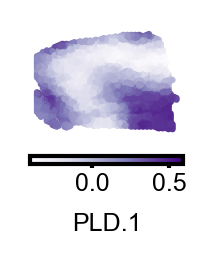

In [168]:
plt.figure(figsize=(0.66, 0.66), dpi=300)
plt.scatter(
    sample_non_unk_df.pos_x,
    sample_non_unk_df.pos_y,
    c=sample_ld[:, 1],
    s=0.5,
    cmap='Purples',
    vmin=training_ld[:, 1].min(),
    vmax=training_ld[:, 1].max(),
)
plt.axis('off')
cbar = plt.colorbar(orientation='horizontal')
cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)
cbar.ax.xaxis.set_tick_params(size=1, pad=1)
cbar.set_label('PLD.1')

## Layers Legend

(0.0, 1.0, 0.0, 1.0)

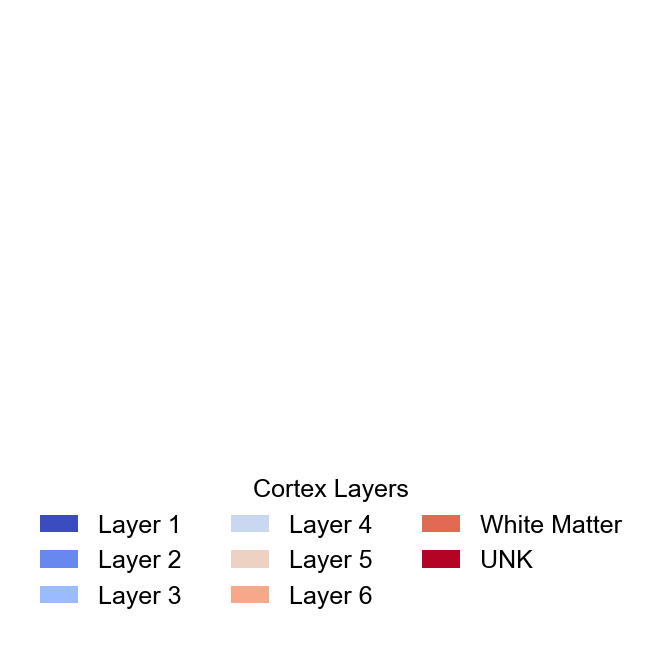

In [53]:
plt.figure(figsize=(1, 2), dpi=300)
handles = [
        matplotlib.patches.Patch(facecolor=plt.cm.coolwarm(i / 7)) for i in range(8)
]

legend = plt.legend(
    handles, 
    ['Layer 1', 'Layer 2', 'Layer 3', 'Layer 4', 'Layer 5', 'Layer 6', 'White Matter', 'UNK'], 
    title='Cortex Layers',
    loc=(-0.95, -0.3),
    frameon=False,
    ncols=3,
    handlelength=1.5,
    prop={'size': 6}
)

plt.axis('off')

## Method Comparison

In [54]:
OTHER_RESULTS_PATH = '/raid/immucan/immuw/tumorhood/tumorhood_bc/notebooks/'

method_to_results = {
    'UTAG': pandas.read_csv(os.path.join(OTHER_RESULTS_PATH, 'ARI_UTAG_hvgs1000_nlatent10_joint.csv')),
    'DR': pandas.read_csv(os.path.join(OTHER_RESULTS_PATH, 'ARI_DR-SC_svg2000_joint.csv')),
    'SEDR': pandas.read_csv(os.path.join(OTHER_RESULTS_PATH, 'ARI_SEDR_feat_hidden2_10_gcn_hidden2_16_pc10_gpu_joint.csv')),
    'Bayes Space': pandas.read_csv(os.path.join(OTHER_RESULTS_PATH, 'ARI_BayesSpace_hvg1000_pc15_gamma3_nrep5000_harmony-group_joint.csv')),
    'Stagate': pandas.read_csv(os.path.join(OTHER_RESULTS_PATH, 'ARI_STAGATE_hvgs5000_hidden_dim1024_nlatent30_gpu_joint.csv')),
    'Cellcharter': pandas.read_csv(os.path.join(OTHER_RESULTS_PATH, 'ARI_CellCharter_hvgs5000_nlatent5_nhoodlayers4_gpu_joint.csv')),
}

method_to_results_means = {
    key: value.values[value['Unnamed: 0'].apply(lambda x: x in NON_TEST_SAMPLES)][:, 1:].mean(axis=1)
    for key, value in method_to_results.items()
}

Text(0.5, 0, 'Method')

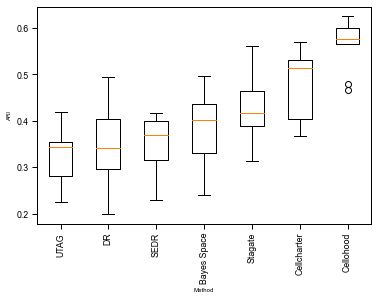

In [55]:
_ = plt.boxplot(
    list(method_to_results_means.values()) + [train_means],
    labels=list(method_to_results_means.keys()) + ['Cellohood'],
)

_ = plt.xticks(rotation=90)
plt.ylabel('ARI')
plt.xlabel('Method')

In [56]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, ConnectionPatch
import seaborn as sns
from scipy import stats

def compute_pvalues(data_lists, reference_idx):
    """
    Compute p-values comparing reference method to all others using two-sided t-test
    
    Parameters:
    -----------
    data_lists : list of lists
        Each inner list contains the scores for one method
    reference_idx : int
        Index of the reference method
        
    Returns:
    --------
    list of float
        P-values for each comparison (None for reference method)
    """
    pvalues = []
    reference_data = data_lists[reference_idx]
    
    for i, data in enumerate(data_lists):
        if i == reference_idx:
            pvalues.append(None)
        else:
            # Perform two-sided t-test
            print(len(data), len(reference_data))
            _, pval = stats.ttest_rel(reference_data, data)
            pvalues.append(pval)
            
    return pvalues

def plot_boxplot_with_stats(data_lists, method_names, my_method_idx, 
                           figsize=(3, 2), my_method_color='lightblue',
                           other_methods_color='lightgray', sig_threshold=0.05):
    """
    Create a boxplot with significance bars connecting to a reference method.
    
    Parameters:
    -----------
    data_lists : list of lists
        Each inner list contains the scores for one method
    method_names : list of str
        Names of the methods
    my_method_idx : int
        Index of your method in the lists
    figsize : tuple
        Figure size
    my_method_color : str
        Color for your method's box
    other_methods_color : str
        Color for other methods' boxes
    sig_threshold : float
        Significance threshold for p-values
    """
    
    # Compute p-values
    pvalues = compute_pvalues(data_lists, my_method_idx)
    print(pvalues)
    
    # Create figure and axis
    fig, ax = plt.subplots(figsize=figsize, dpi=300)
    
    # Create colors list
    colors = [other_methods_color] * len(method_names)
    colors[my_method_idx] = my_method_color
    
    # Create boxplot
    box_ratio = 1.25
    bplot = ax.boxplot(data_lists, patch_artist=True, positions=box_ratio * numpy.arange(len(colors)))
    
    # Color the boxes
    for patch, color in zip(bplot['boxes'], colors):
        patch.set_facecolor(color)
    
    # Set the labels
    ax.set_xticklabels(method_names, rotation=30, ha='right', size=6)
    
    # Get the positions of boxes for connecting lines
    my_method_pos = my_method_idx + 1  # boxplot positions start at 1
    
    # Get the maximum value in the data for scaling
    max_val = max([max(sublist) for sublist in data_lists])
    min_val = min([min(sublist) for sublist in data_lists])
    plot_range = max_val - min_val
    
    # Space between bars
    step = plot_range * 0.1
    
    # Draw connecting lines and p-values
    for i, (pval, data) in enumerate(zip(pvalues, data_lists)):
        if i != my_method_idx:
            # Calculate height for this comparison
            curr_pos = i + 1  # boxplot positions start at 1
            height = max_val + step * (0.1 + abs(curr_pos)) * 1.3
            
            # Draw the line
            x1, x2 = sorted([my_method_pos, curr_pos])
            x1 = x1 * box_ratio - box_ratio
            x2 = x2 * box_ratio - box_ratio
            line = plt.hlines(y=height, xmin=x1, xmax=x2, color='black', linestyle='-', linewidth=0.6)
            
            # Add vertical line
            plt.vlines(x=x1, ymin=height - 0.01, ymax=height, color='black', linestyle='-', linewidth=0.6)
            plt.vlines(x=x2, ymin=height - 0.01, ymax=height, color='black', linestyle='-', linewidth=0.6)
            
            # Add p-value annotation
            text_pos = (x1 + x2) / 2
            
            # Format p-value
            if pval < 0.001:
                pval_text = 'p < 0.001'
            else:
                pval_text = f'p = {pval:.3f}'
            
            # Add asterisks for significance
            if pval < sig_threshold:
                asterisks = '*' * sum([pval < thresh for thresh in [0.05, 0.01, 0.001]])
                pval_text = f'{pval_text} ({asterisks})'
            
            plt.text(text_pos, height + step*0.1, pval_text, size=6,
                    horizontalalignment='center', verticalalignment='bottom')
    
    plt.plot([-0.5, 7.], [numpy.median(train_means)] * 2, '--', c='orange', linewidth=0.5)
    plt.text(
        -0.25, 
        numpy.median(train_means) + 0.01, 
        f'Cellohood Median Score (ARI={round(numpy.median(train_means), 2)})', size=6, style='italic')
    
    # Adjust the plot limits to show all bars
    #plt.ylim(min_val - 0.05, max_val + 0.05)
    #plt.axes(frameon=False)
    
    # Add labels and title
    plt.ylabel('ARI', size=6, labelpad=1)
    plt.xlabel('Method', size=6, labelpad=1)
    ax.set_yticklabels(ax.get_yticklabels(), size=6)
    ax.set_xticklabels(ax.get_xticklabels(), size=6)
    ax.spines[['right', 'top']].set_visible(False)
    #ax.set_aspect(6)
    ax.yaxis.set_tick_params(size=1, pad=1)
    ax.xaxis.set_tick_params(size=1, pad=1)
    #ax.set_ylim([0, 1.])
    
    # Adjust layout to prevent label cutoff
    #plt.tight_layout()
    
    return fig, ax, pvalues



9 9
9 9
9 9
9 9
9 9
9 9
[2.70749012859218e-07, 0.0011215362836663788, 2.5374583713468347e-07, 5.522645428498212e-06, 0.00015208818340437986, 0.0020561530299759447, None]


/tmp/ipykernel_3696825/2788080153.py:141: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)


(<Figure size 900x600 with 1 Axes>,
 <Axes: xlabel='Method', ylabel='ARI'>,
 [2.70749012859218e-07,
  0.0011215362836663788,
  2.5374583713468347e-07,
  5.522645428498212e-06,
  0.00015208818340437986,
  0.0020561530299759447,
  None])

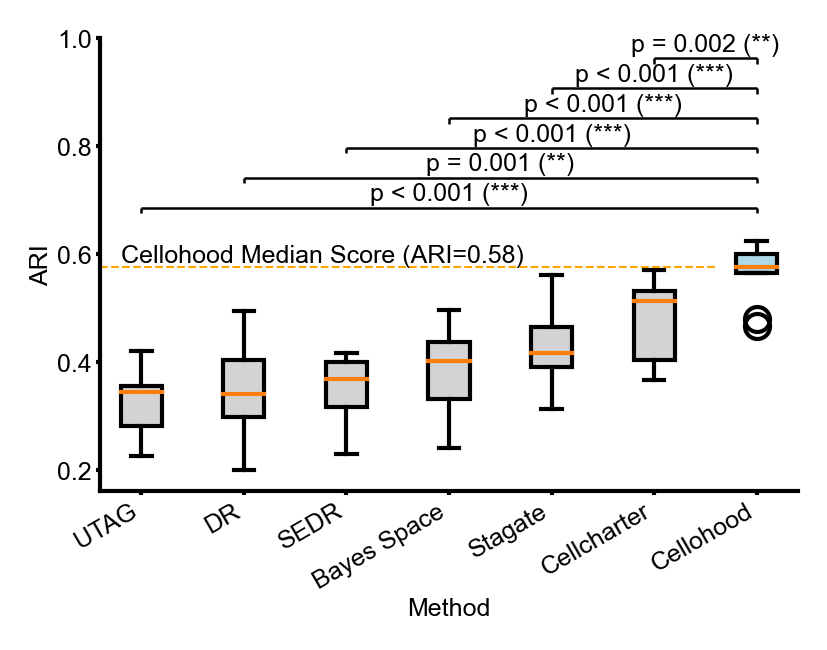

In [57]:
plot_boxplot_with_stats(
    list(method_to_results_means.values()) + [train_means],
    list(method_to_results_means.keys()) + ['Cellohood'],
    len(list(method_to_results_means.values()) + [train_means]) - 1,
)

## Diffusion maps

In [58]:
import pydiffmap

diffusion_transformer = pydiffmap.diffusion_map.DiffusionMap.from_sklearn(
    n_evecs=2, 
    epsilon=0.01, 
    alpha=.1, 
    k=64,
)

In [59]:
diffusion_transformer.fit(decomposed[::20, [0, 1]] / decomposer.explained_variance_[:2] ** 0.5)
diffusion_transformed_ld = diffusion_transformer.transform(decomposed[:, [0, 1]]  / decomposer.explained_variance_[:2] ** 0.5)

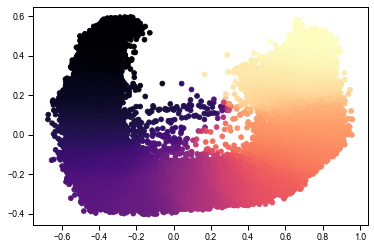

In [60]:
plt.scatter(
    decomposed[:, 0],
    decomposed[:, 1],
    c=diffusion_transformed_ld[:, 0],
    cmap='magma',
)

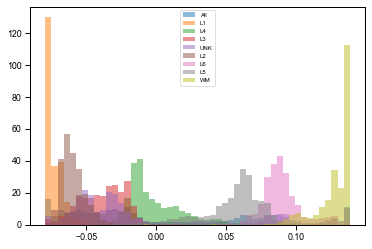

In [61]:
_, bins, _ = plt.hist(
    diffusion_transformed_ld[:, 0],
    density=True, 
    alpha=0.5,
    label='All',
    bins=50
)

for layer in set(bag_cello_df.cell_df['layer']):
    plt.hist(
        diffusion_transformed_ld[bag_cello_df.cell_df['layer'] == layer, 0],
        density=True, 
        bins=bins,
        alpha=0.5,
        label=layer
    )
plt.legend()

  0%|                                                                                                                                                                                | 0/10 [00:00<?, ?it/s]

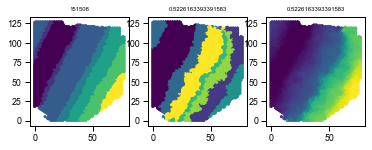

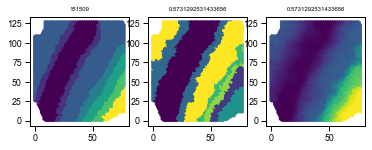

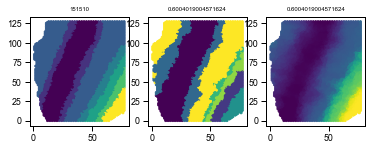

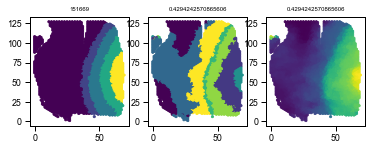

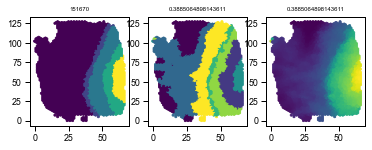

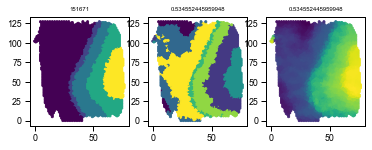

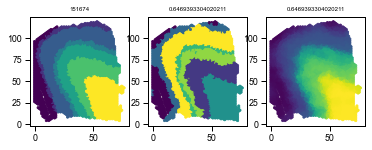

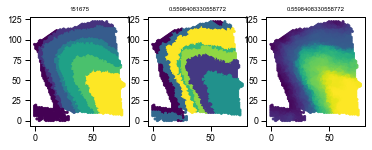

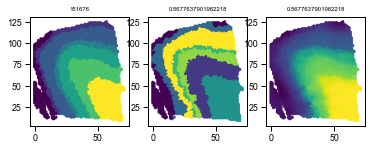

 10%|████████████████▊                                                                                                                                                       | 1/10 [00:05<00:53,  5.95s/it]

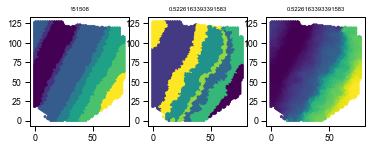

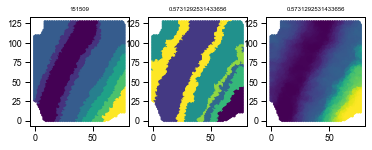

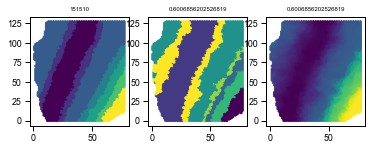

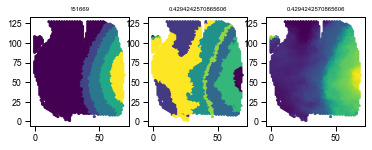

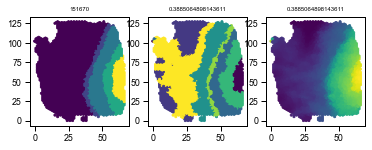

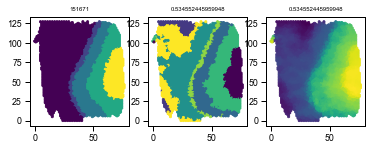

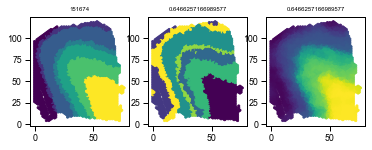

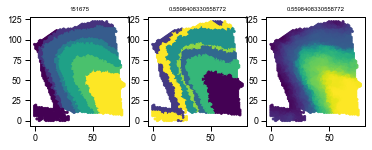

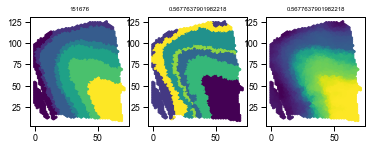

 20%|█████████████████████████████████▌                                                                                                                                      | 2/10 [00:11<00:43,  5.50s/it]

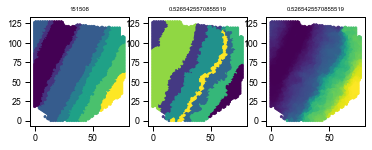

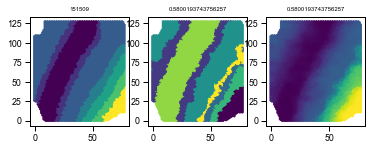

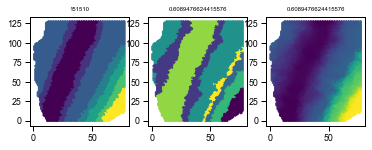

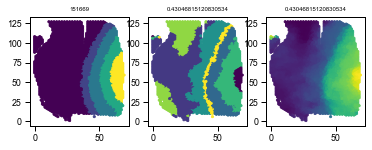

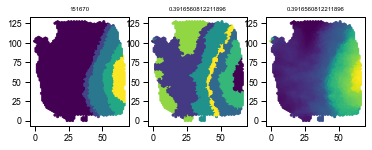

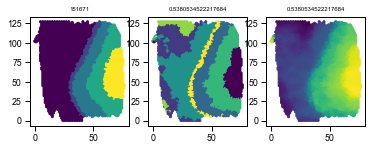

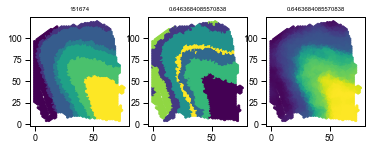

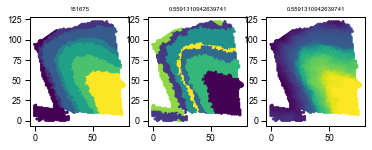

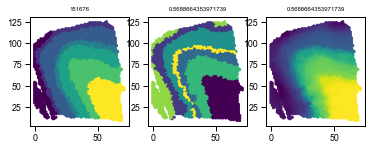

 30%|██████████████████████████████████████████████████▍                                                                                                                     | 3/10 [00:15<00:34,  4.97s/it]

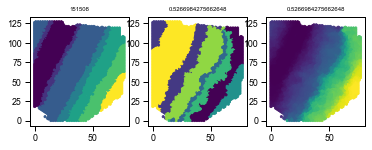

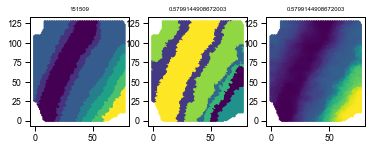

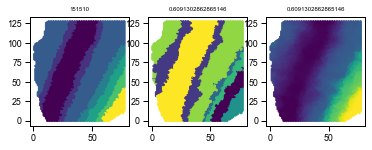

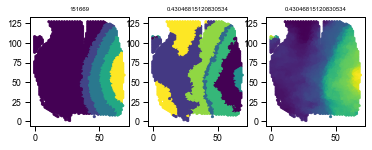

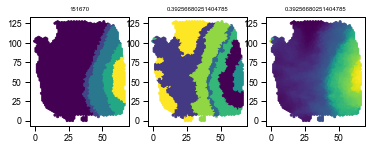

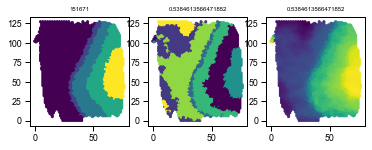

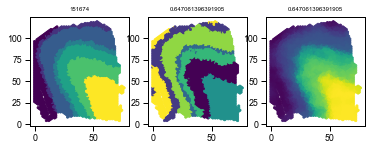

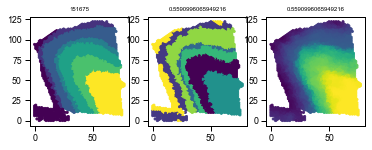

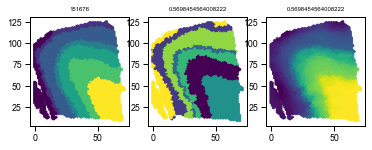

 40%|███████████████████████████████████████████████████████████████████▏                                                                                                    | 4/10 [00:22<00:35,  5.90s/it]

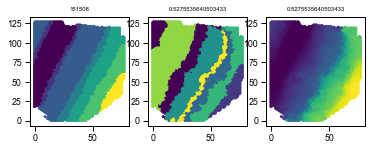

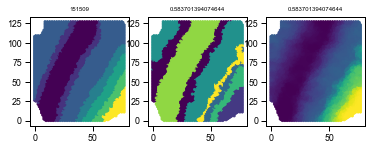

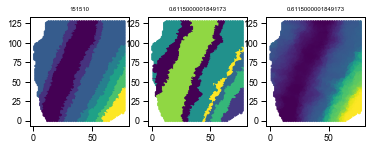

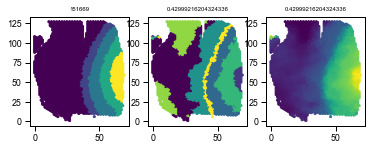

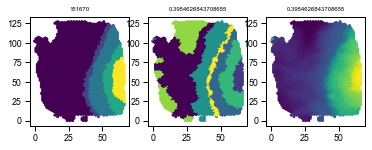

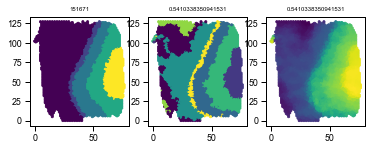

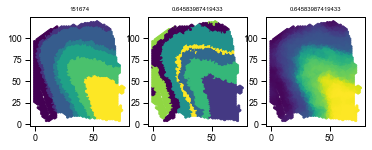

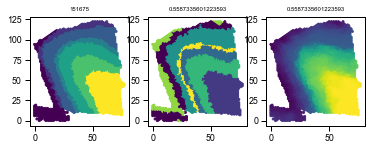

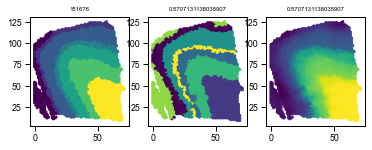

 50%|████████████████████████████████████████████████████████████████████████████████████                                                                                    | 5/10 [00:26<00:26,  5.29s/it]

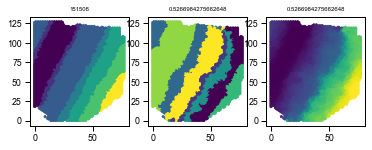

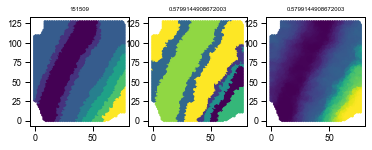

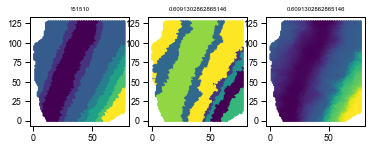

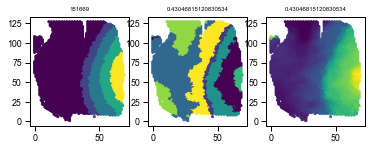

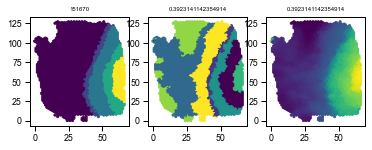

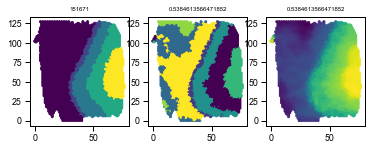

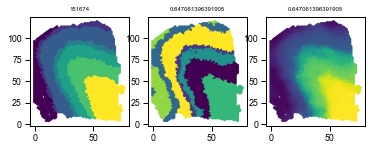

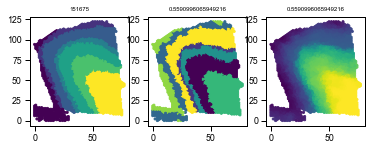

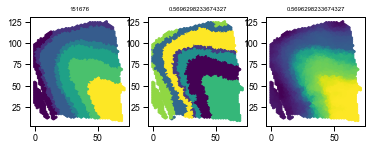

 60%|████████████████████████████████████████████████████████████████████████████████████████████████████▊                                                                   | 6/10 [00:33<00:22,  5.73s/it]

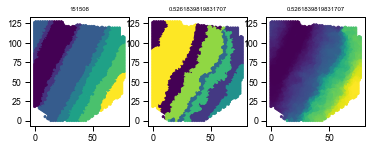

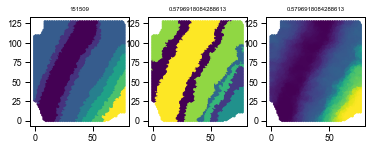

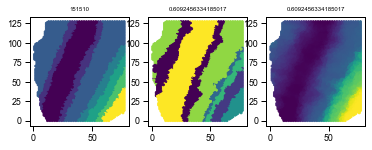

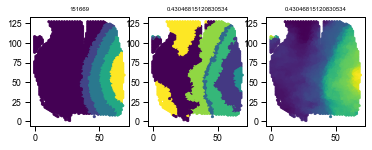

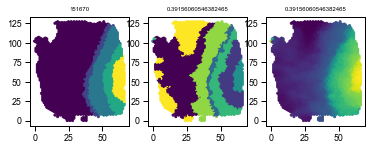

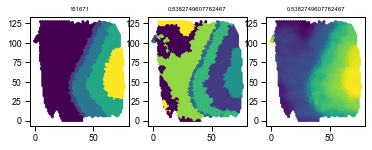

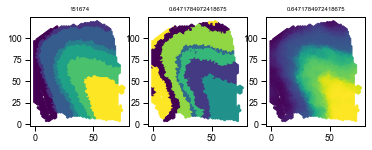

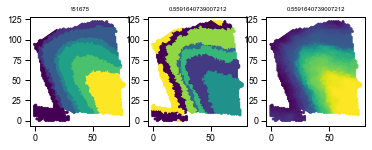

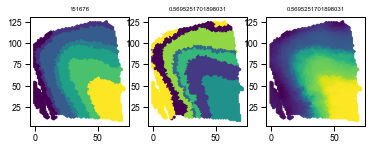

 70%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▌                                                  | 7/10 [00:39<00:17,  5.73s/it]

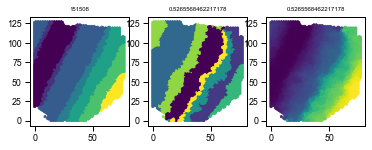

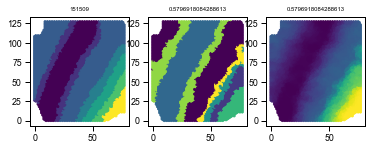

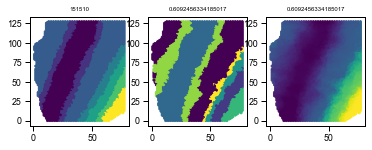

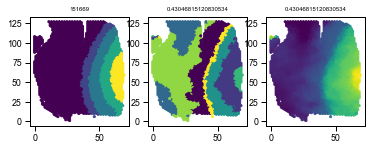

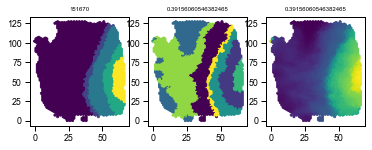

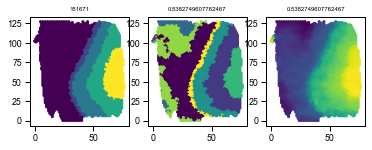

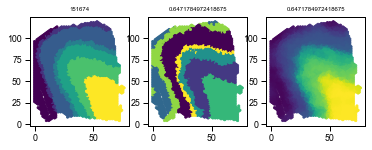

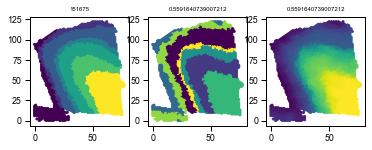

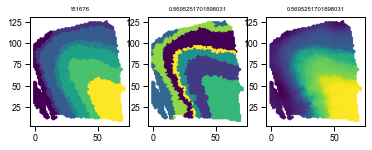

 80%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▍                                 | 8/10 [00:45<00:11,  5.91s/it]

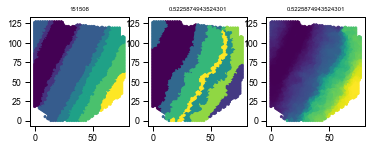

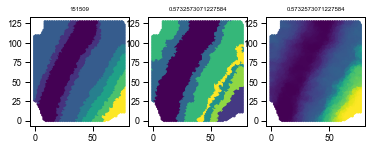

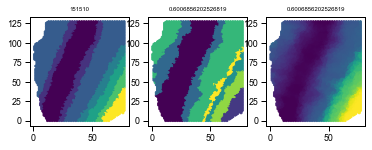

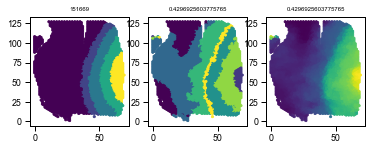

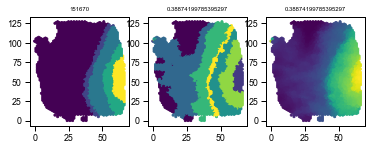

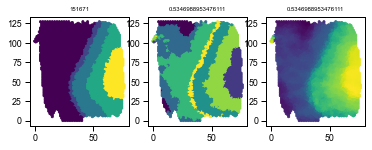

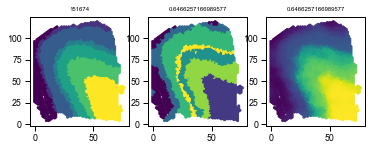

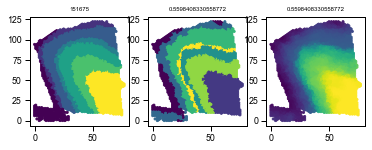

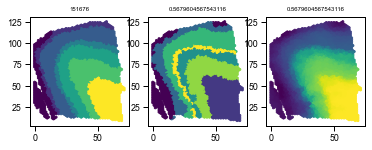

 90%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▏                | 9/10 [00:50<00:05,  5.58s/it]

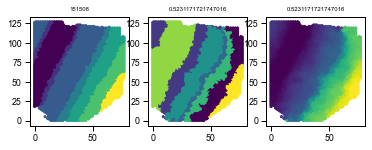

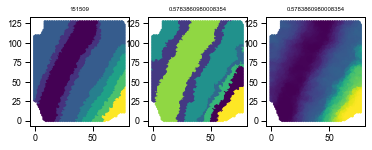

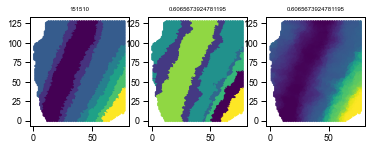

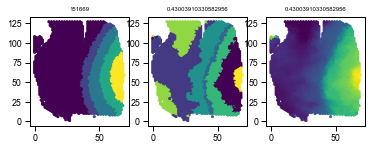

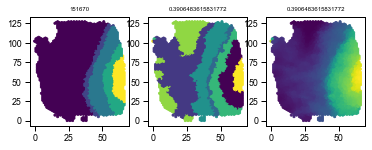

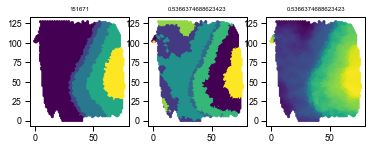

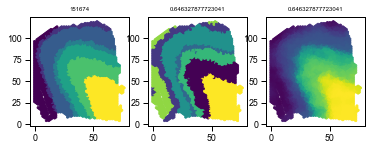

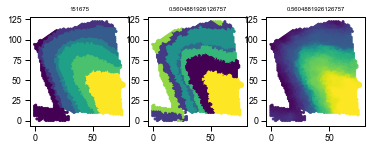

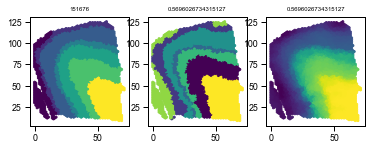

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10/10 [00:55<00:00,  5.50s/it]


In [62]:
from collections import defaultdict
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_mutual_info_score, adjusted_rand_score


from scipy.stats import ttest_rel
import numpy
import tqdm



NB_OF_RUNS = 10


# From Cellcharter paper
TEST_SAMPLES = [
    151507,
    151672,
    151673
]

NON_TEST_SAMPLES = [
    sample 
    for sample in sorted(bag_cello_df.cell_df['sample'].unique())
    if sample not in TEST_SAMPLES
]


current_random_seed = 42
sample_to_aris_diff = defaultdict(list)
clusterers_diff = []
variables = [0]

train_cello_df = bag_cello_df.cell_df[bag_cello_df.cell_df['sample'].apply(lambda x: x not in TEST_SAMPLES)]


for _ in tqdm.tqdm(range(NB_OF_RUNS)):
    # Fitting the model
    current_clusterer = GaussianMixture(7, random_state=current_random_seed)
    current_random_seed += 1
    training_ld_diff = diffusion_transformed_ld[
        bag_cello_df.cell_df['sample'].apply(lambda x: x not in TEST_SAMPLES),
    ][:, variables]
    current_clusterer.fit(training_ld_diff)
    clusterers_diff.append(current_clusterer)
    
    # Running prediction on samples
    for sample in sorted(bag_cello_df.cell_df['sample'].unique()):
        if sample in TEST_SAMPLES:
            continue
        sample_all_df = bag_cello_df.cell_df[bag_cello_df.cell_df['sample'] == sample]
        sample_non_unk_df = sample_all_df[sample_all_df['layer'] != 'UNK']
        
        sample_ld = training_ld_diff[train_cello_df['sample'] == sample][:, variables]
        sample_ld = sample_ld[(sample_all_df['layer'] != 'UNK').values]
        sample_gt = sample_non_unk_df['layer'].apply(lambda x: layers_.index(x))
        
        sample_preds = current_clusterer.predict(sample_ld)
        current_ari = adjusted_rand_score(sample_preds, sample_gt)
        
        sample_to_aris_diff[sample].append(current_ari)
        
        plt.figure(figsize=(6, 2))
        plt.subplot(1, 3, 1)
        plt.scatter(
            sample_non_unk_df.pos_x,
            sample_non_unk_df.pos_y,
            c=sample_non_unk_df['layer'].apply(lambda x: layers_.index(x)),
            s=5,
        )
        plt.title(sample)
        plt.subplot(1, 3, 2)
        plt.scatter(
            sample_non_unk_df.pos_x,
            sample_non_unk_df.pos_y,
            c=sample_preds,
            s=5,
        )
        plt.title(current_ari)
        plt.subplot(1, 3, 3)
        plt.scatter(
            sample_non_unk_df.pos_x,
            sample_non_unk_df.pos_y,
            c=sample_ld[:, 0],
            s=5,
        )
        plt.title(current_ari)
        plt.show()

NameError: name 'means' is not defined

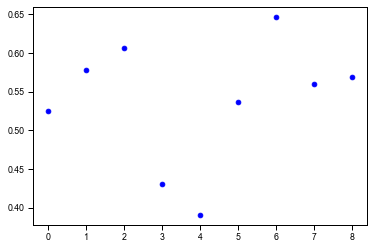

In [63]:
means_diff = []
for sample_id, sample in enumerate(sorted(sample_to_aris_diff)):
    means_diff.append(numpy.mean(sample_to_aris_diff[sample]))
plt.scatter(
    list(range(9)),
    means_diff,
    c='b',
    label='Cello Diff'
)
plt.scatter(
    list(range(9)),
    means,
    c='g',
    label='Cello'
)
ch_median = numpy.median(means)
ch_median_diff = numpy.median(means_diff)
cch_median = numpy.median(numpy.median(cellcharter.values[:, 1:].mean(axis=1)))
plt.plot([0, 8], [ch_median_diff, ch_median_diff],  '--', c='b', alpha=0.5)
plt.plot([0, 8], [ch_median, ch_median],  '--', c='g', alpha=0.5)
plt.scatter(
        list(range(9)),
        cellcharter.values[:, 1:].mean(axis=1),
        c='r',
        label='CellCharter',
    )
ttest = ttest_rel(means_diff, cellcharter.values[:, 1:].mean(axis=1)).pvalue
plt.title(f'{2}: T-test p value {ttest}')
plt.plot([0, 8], [cch_median, cch_median], '--', c='r', alpha=0.5)
plt.legend()

/tmp/ipykernel_3696825/1584708877.py:63: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_3696825/1584708877.py:65: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)
/tmp/ipykernel_3696825/1584708877.py:63: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_3696825/1584708877.py:65: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)
/tmp/ipykernel_3696825/1584708877.py:63: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_3696825/1584708877.py:65: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6

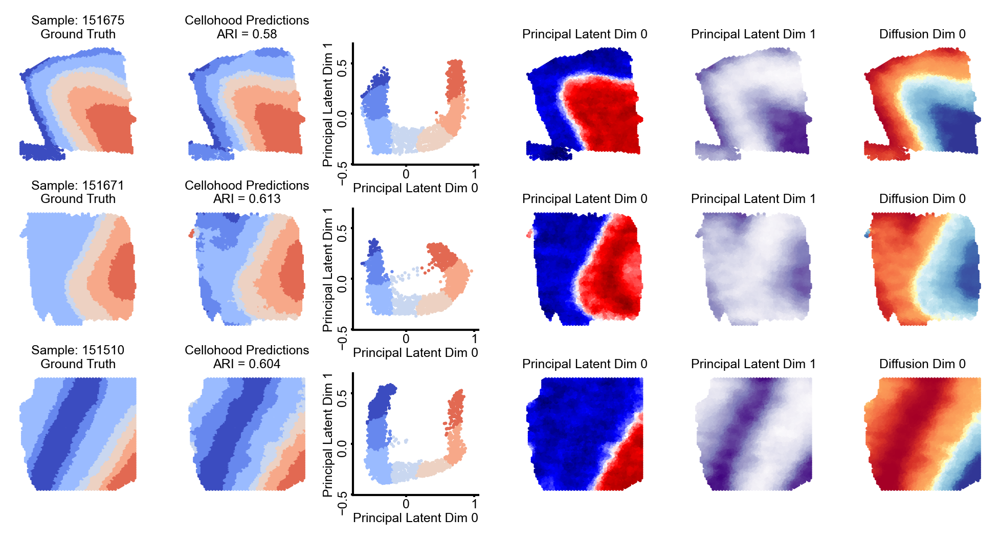

In [64]:
plt.figure(figsize=(6.5, 3.5), dpi=300)


variables = [0, 1]


for sample_id, sample in enumerate(PANEL_A_SAMPLES):
    sample_all_df = bag_cello_df.cell_df[bag_cello_df.cell_df['sample'] == sample]
    sample_non_unk_df = sample_all_df[sample_all_df['layer'] != 'UNK']

    sample_ld = decomposed[bag_cello_df.cell_df['sample'] == sample][:, variables]
    sample_ld = sample_ld[(sample_all_df['layer'] != 'UNK').values]
    sample_gt = sample_non_unk_df['layer'].apply(lambda x: layers_.index(x))
    sample_diff_d = diffusion_transformed_ld[bag_cello_df.cell_df['sample'] == sample]
    sample_diff_d = sample_diff_d[(sample_all_df['layer'] != 'UNK').values]

    sample_preds = best_clusterer.predict(sample_ld)
    current_ari = adjusted_rand_score(sample_preds, sample_gt)

    sample_to_aris[sample].append(current_ari)

    
    plt.subplot(3, 6, 6 * sample_id + 1)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=sample_non_unk_df['layer'].apply(lambda x: true_layers.index(x)),
        cmap='coolwarm',
        s=0.5,
        vmax=7,
        vmin=0,
    )
    plt.axis('off')
    plt.title(f'Sample: {sample}\nGround Truth', pad=2.5, size=6)
    plt.subplot(3, 6, 6 * sample_id + 2)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=[true_layers.index(pred_to_layer_assignment[x]) for x in sample_preds],
        s=0.5,
        cmap='coolwarm',
        vmax=7,
        vmin=0,
    )
    plt.axis('off')
    plt.title(f'Cellohood Predictions\nARI = {round(current_ari, 3)}', pad=2.5, size=6)
    plt.subplot(3, 6, 6 * sample_id + 3)
    plt.scatter(
        sample_ld[:, 0],
        sample_ld[:, 1],
        c=[true_layers.index(pred_to_layer_assignment[x]) for x in sample_preds],
        s=0.5,
        cmap='coolwarm',
        vmax=7,
        vmin=0,
    )
    plt.xlim([training_ld[:, 0].min() - 0.1, training_ld[:, 0].max() + 0.1])
    plt.ylim([training_ld[:, 1].min() - 0.1, training_ld[:, 1].max() + 0.1])
    ax = plt.gca()
    ax.xaxis.set_tick_params(size=1, pad=1)
    ax.set_xlabel('Principal Latent Dim 0', size=6, labelpad=1)
    ax.set_ylabel('Principal Latent Dim 1', size=6, labelpad=1)
    ax.set_xticklabels(ax.get_xticklabels(), size=6)
    ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
    ax.set_yticklabels(ax.get_yticklabels(), size=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.subplot(3, 6, 6 * sample_id + 4)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=sample_ld[:, 0],
        s=0.5,
        vmin=training_ld[:, 0].min(),
        vmax=training_ld[:, 0].max(),
        cmap='seismic',
    )
    #plt.colorbar()
    plt.axis('off')
    plt.title(f'Principal Latent Dim 0', pad=2.5, size=6)
    plt.subplot(3, 6, 6 * sample_id + 5)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=sample_ld[:, 1],
        s=0.5,
        cmap='Purples',
        vmin=training_ld[:, 1].min(),
        vmax=training_ld[:, 1].max(),
    )
    plt.axis('off')
    plt.title(f'Principal Latent Dim 1', pad=2.5, size=6)
    plt.subplot(3, 6, 6 * sample_id + 6)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=sample_diff_d[:, 0],
        s=0.5,
        cmap='RdYlBu',
        vmin=diffusion_transformed_ld[:, 0].min(),
        vmax=diffusion_transformed_ld[:, 0].max(),
    )
    plt.axis('off')
    plt.title(f'Diffusion Dim 0', pad=2.5, size=6)
    #plt.colorbar()
    #ax.set_title('Spot Latent Representations', size=6, pad=2.5)
plt.subplots_adjust(hspace=0.25, wspace=0.25)
plt.tight_layout()

In [65]:
ALL_SAMPLES = sorted(set(bag_cello_df.cell_df['sample']))

/tmp/ipykernel_3696825/4171360802.py:66: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_3696825/4171360802.py:68: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)
/tmp/ipykernel_3696825/4171360802.py:66: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_3696825/4171360802.py:68: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)
/tmp/ipykernel_3696825/4171360802.py:66: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_3696825/4171360802.py:68: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6

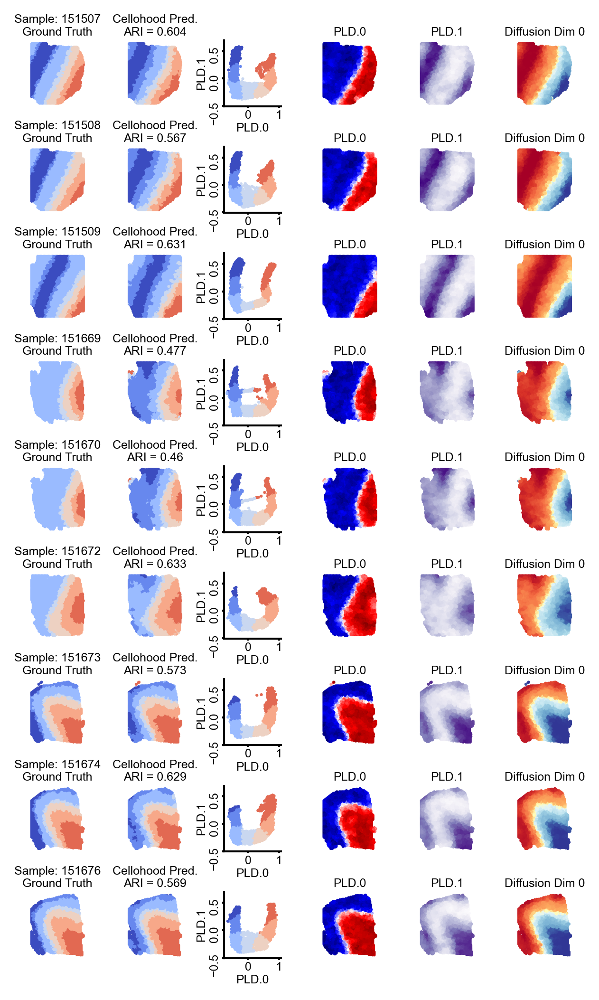

In [155]:
plt.figure(figsize=(4, 7), dpi=300)


variables = [0, 1]

REST_SAMPLES = [sample for sample in ALL_SAMPLES if sample not in PANEL_A_SAMPLES]

for sample_id, sample in enumerate(REST_SAMPLES):
    if sample in PANEL_A_SAMPLES:
        continue
    sample_all_df = bag_cello_df.cell_df[bag_cello_df.cell_df['sample'] == sample]
    sample_non_unk_df = sample_all_df[sample_all_df['layer'] != 'UNK']

    sample_ld = decomposed[bag_cello_df.cell_df['sample'] == sample][:, variables]
    sample_ld = sample_ld[(sample_all_df['layer'] != 'UNK').values]
    sample_gt = sample_non_unk_df['layer'].apply(lambda x: layers_.index(x))
    sample_diff_d = diffusion_transformed_ld[bag_cello_df.cell_df['sample'] == sample]
    sample_diff_d = sample_diff_d[(sample_all_df['layer'] != 'UNK').values]

    sample_preds = best_clusterer.predict(sample_ld)
    current_ari = adjusted_rand_score(sample_preds, sample_gt)

    sample_to_aris[sample].append(current_ari)

    
    plt.subplot(9, 6, 6 * sample_id + 1)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=sample_non_unk_df['layer'].apply(lambda x: true_layers.index(x)),
        cmap='coolwarm',
        s=0.5,
        vmax=7,
        vmin=0,
    )
    plt.axis('off')
    plt.title(f'Sample: {sample}\nGround Truth', pad=2.5, size=6)
    plt.subplot(9, 6, 6 * sample_id + 2)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=[true_layers.index(pred_to_layer_assignment[x]) for x in sample_preds],
        s=0.5,
        cmap='coolwarm',
        vmax=7,
        vmin=0,
    )
    plt.axis('off')
    plt.title(f'Cellohood Pred.\nARI = {round(current_ari, 3)}', pad=2.5, size=6)
    plt.subplot(9, 6, 6 * sample_id + 3)
    plt.scatter(
        sample_ld[:, 0],
        sample_ld[:, 1],
        c=[true_layers.index(pred_to_layer_assignment[x]) for x in sample_preds],
        s=0.5,
        cmap='coolwarm',
        vmax=7,
        vmin=0,
    )
    plt.xlim([decomposed[:, 0].min() - 0.1, decomposed[:, 0].max() + 0.1])
    plt.ylim([decomposed[:, 1].min() - 0.1, decomposed[:, 1].max() + 0.1])
    ax = plt.gca()
    ax.xaxis.set_tick_params(size=1, pad=1)
    ax.set_xlabel('PLD.0', size=6, labelpad=1)
    ax.set_ylabel('PLD.1', size=6, labelpad=1)
    ax.set_xticklabels(ax.get_xticklabels(), size=6)
    ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
    ax.set_yticklabels(ax.get_yticklabels(), size=6)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    plt.subplot(9, 6, 6 * sample_id + 4)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=sample_ld[:, 0],
        s=0.5,
        vmin=decomposed[:, 0].min(),
        vmax=decomposed[:, 0].max(),
        cmap='seismic',
    )
    #plt.colorbar()
    plt.axis('off')
    plt.title(f'PLD.0', pad=2.5, size=6)
    plt.subplot(9, 6, 6 * sample_id + 5)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=sample_ld[:, 1],
        s=0.5,
        cmap='Purples',
        vmin=decomposed[:, 1].min(),
        vmax=decomposed[:, 1].max(),
    )
    plt.axis('off')
    plt.title(f'PLD.1', pad=2.5, size=6)
    plt.subplot(9, 6, 6 * sample_id + 6)
    plt.scatter(
        sample_non_unk_df.pos_x,
        sample_non_unk_df.pos_y,
        c=sample_diff_d[:, 0],
        s=0.5,
        cmap='RdYlBu',
        vmin=diffusion_transformed_ld[:, 0].min(),
        vmax=diffusion_transformed_ld[:, 0].max(),
    )
    plt.axis('off')
    plt.title(f'Diffusion Dim 0', pad=2.5, size=6)
    #plt.colorbar()
    #ax.set_title('Spot Latent Representations', size=6, pad=2.5)
plt.subplots_adjust(hspace=0.25, wspace=0.25)
plt.tight_layout()

## Diffusion direction colorbar

/tmp/ipykernel_3696825/532637280.py:13: UserWarning: FixedFormatter should only be used together with FixedLocator
  cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)


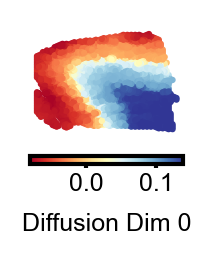

In [164]:
plt.figure(figsize=(0.66, 0.66), dpi=300)
plt.scatter(
    sample_non_unk_df.pos_x,
    sample_non_unk_df.pos_y,
    c=sample_diff_d[:, 0],
    s=0.5,
    cmap='RdYlBu',
    vmin=diffusion_transformed_ld[:, 0].min(),
    vmax=diffusion_transformed_ld[:, 0].max(),
)
plt.axis('off')
cbar = plt.colorbar(orientation='horizontal')
cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)
cbar.ax.xaxis.set_tick_params(size=1, pad=1)
cbar.set_label('Diffusion Dim 0')

In [ ]:
plt.figure(figsize=(0.66, 0.66), dpi=300)
plt.scatter(
    sample_non_unk_df.pos_x,
    sample_non_unk_df.pos_y,
    c=sample_diff_d[:, 0],
    s=0.5,
    cmap='RdYlBu',
    vmin=diffusion_transformed_ld[:, 0].min(),
    vmax=diffusion_transformed_ld[:, 0].max(),
)
plt.axis('off')
cbar = plt.colorbar(orientation='horizontal')
cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)
cbar.ax.xaxis.set_tick_params(size=1, pad=1)
cbar.set_label('Diffusion Dim 0')

/tmp/ipykernel_3696825/708998932.py:13: UserWarning: FixedFormatter should only be used together with FixedLocator
  cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)


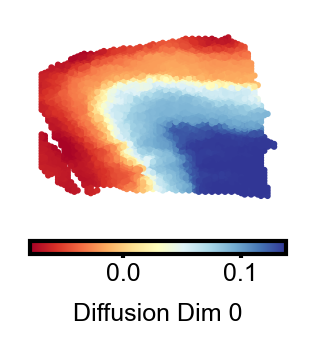

In [165]:
plt.figure(figsize=(1.1, 1.1), dpi=300)
plt.scatter(
    sample_non_unk_df.pos_x,
    sample_non_unk_df.pos_y,
    c=sample_diff_d[:, 0],
    s=0.5,
    cmap='RdYlBu',
    vmin=diffusion_transformed_ld[:, 0].min(),
    vmax=diffusion_transformed_ld[:, 0].max(),
)
plt.axis('off')
cbar = plt.colorbar(orientation='horizontal')
cbar.set_ticklabels(cbar.ax.get_xticklabels(), size=6)
cbar.ax.xaxis.set_tick_params(size=1, pad=1)
cbar.set_label('Diffusion Dim 0')

## Latent Figures

In [68]:
all_preds = best_clusterer.predict(decomposed[:, [0, 1]])

In [69]:
true_layers_wu = true_layers + ['UNK']

/tmp/ipykernel_3696825/2188050068.py:20: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_3696825/2188050068.py:22: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)
/tmp/ipykernel_3696825/2188050068.py:41: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_3696825/2188050068.py:43: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)
/tmp/ipykernel_3696825/2188050068.py:64: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(ax.get_xticklabels(), size=6)
/tmp/ipykernel_3696825/2188050068.py:66: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6

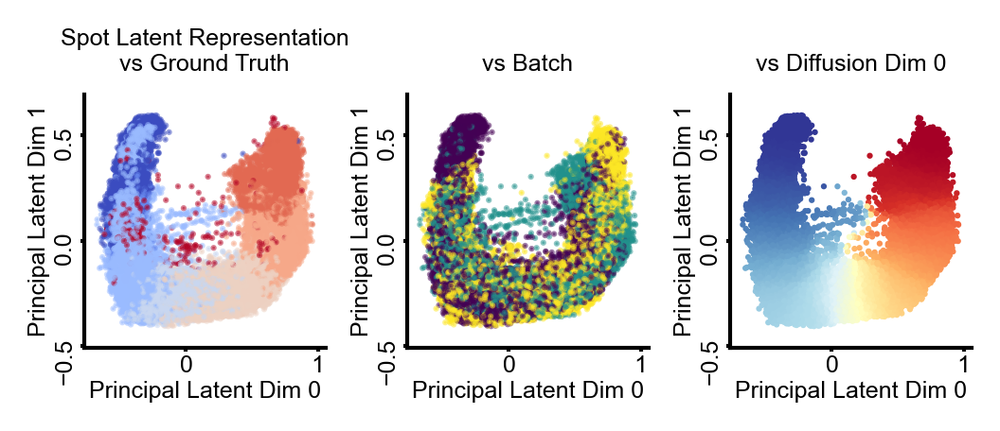

In [70]:
plt.figure(figsize=(3.5, 1.5), dpi=300)

plt.subplot(1, 3, 1)
plt.scatter(
    decomposed[:, 0],
    decomposed[:, 1],
    c=[true_layers_wu.index(x) for x in bag_cello_df.cell_df['layer']],
    s=0.5,
    cmap='coolwarm',
    alpha=0.5,
    vmax=7,
    vmin=0,
)
plt.xlim([decomposed[:, 0].min() - 0.1, decomposed[:, 0].max() + 0.1])
plt.ylim([decomposed[:, 1].min() - 0.1, decomposed[:, 1].max() + 0.1])
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, pad=1)
ax.set_xlabel('Principal Latent Dim 0', size=6, labelpad=1)
ax.set_ylabel('Principal Latent Dim 1', size=6, labelpad=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title('Spot Latent Representation\nvs Ground Truth')

plt.subplot(1, 3, 3)
plt.scatter(
    decomposed[:, 0],
    decomposed[:, 1],
    c=-diffusion_transformed_ld[:, 0],
    s=0.5,
    cmap='RdYlBu',
)
plt.xlim([decomposed[:, 0].min() - 0.1, decomposed[:, 0].max() + 0.1])
plt.ylim([decomposed[:, 1].min() - 0.1, decomposed[:, 1].max() + 0.1])
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, pad=1)
ax.set_xlabel('Principal Latent Dim 0', size=6, labelpad=1)
ax.set_ylabel('Principal Latent Dim 1', size=6, labelpad=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title('\nvs Diffusion Dim 0')

random_perm = numpy.random.permutation(len(decomposed[:, 0]))

plt.subplot(1, 3, 2)
plt.scatter(
    decomposed[random_perm, 0],
    decomposed[random_perm, 1],
    c=bag_cello_df.cell_df['batch'][random_perm],
    s=0.5,
    alpha=0.5,
)
plt.xlim([decomposed[:, 0].min() - 0.1, decomposed[:, 0].max() + 0.1])
plt.ylim([decomposed[:, 1].min() - 0.1, decomposed[:, 1].max() + 0.1])
ax = plt.gca()
ax.xaxis.set_tick_params(size=1, pad=1)
ax.set_xlabel('Principal Latent Dim 0', size=6, labelpad=1)
ax.set_ylabel('Principal Latent Dim 1', size=6, labelpad=1)
ax.set_xticklabels(ax.get_xticklabels(), size=6)
ax.yaxis.set_tick_params(size=1, pad=1, rotation=90)
ax.set_yticklabels(ax.get_yticklabels(), size=6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_title('\nvs Batch')
plt.tight_layout()

## Batch Legend

In [71]:
bag_cello_df.cell_df.groupby(['sample', 'batch']).size()

sample  batch
151507  0        4226
151508  0        4384
151509  0        4789
151510  0        4634
151669  1        3661
151670  1        3498
151671  1        4110
151672  1        4015
151673  2        3639
151674  2        3673
151675  2        3592
151676  2        3460
dtype: int64

(0.0, 1.0, 0.0, 1.0)

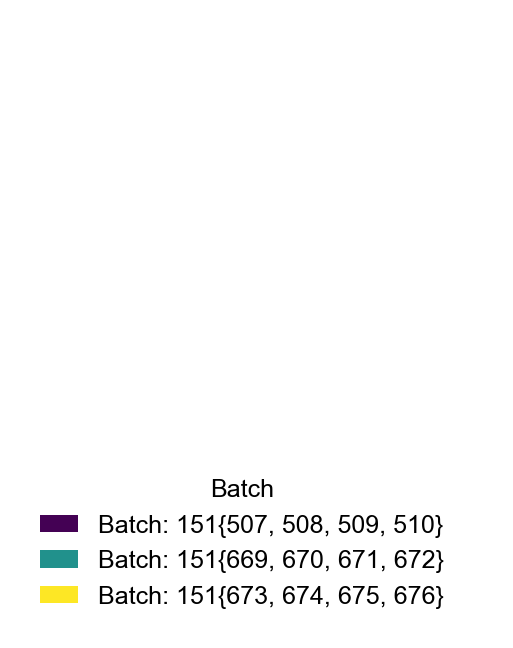

In [72]:
plt.figure(figsize=(1, 2), dpi=300)
handles = [
        matplotlib.patches.Patch(facecolor=plt.cm.viridis(i / 2)) for i in range(3)
]

legend = plt.legend(
    handles, 
    [
        'Batch: 151{507, 508, 509, 510}', 
        'Batch: 151{669, 670, 671, 672}', 
        'Batch: 151{673, 674, 675, 676}',
    ], 
    title='Batch',
    loc=(-0.95, -0.3),
    frameon=False,
    ncols=1,
    handlelength=1.5,
    prop={'size': 6}
)

plt.axis('off')

## Gene programs

In [73]:
zeng_gene_program = pandas.read_csv('/raid/immucan/immuw/data/dlpfc/HumanPilot/Zeng_Markers.csv')
may_gene_program = pandas.read_excel('/raid/immucan/immuw/data/dlpfc/HumanPilot/cortical layer marker gene list_1.xlsx')

In [74]:
gene_expressions = pandas.read_csv('/raid/immucan/immuw/data/dlpfc.csv')

In [75]:
gene_expressions = gene_expressions.iloc[bag_cello_df.cell_df['Unnamed: 0']]

In [76]:
all_genes = list(gene_expressions.columns)[1:-4]

In [77]:
zeng_genes = list(set(zeng_gene_program['Gene'].apply(lambda x: x.upper())) & set(all_genes))
may_genes = list(set(may_gene_program['Gene'].apply(lambda x: x.upper())) & set(all_genes))

In [78]:
zeng_gene_program['Gene'] = zeng_gene_program['Gene'].apply(lambda x: x.upper())
may_gene_program['Gene'] = may_gene_program['Gene'].apply(lambda x: x.upper())

In [79]:
zeng_gene_program.set_index('Gene', inplace=True)
may_gene_program.set_index('Gene', inplace=True)

In [80]:
import tqdm
import scipy


NB_OF_DIRECTIONS = 1

zang_and_may = list(set(zeng_genes + may_genes))


correlations = numpy.zeros((len(zang_and_may), NB_OF_DIRECTIONS))
correlations_p = numpy.zeros((len(zang_and_may), NB_OF_DIRECTIONS))


for s in range(NB_OF_DIRECTIONS):
    print(s)
    for marker_nb, marker in tqdm.tqdm(enumerate(zang_and_may)):
        result = scipy.stats.spearmanr(
            gene_expressions[marker], diffusion_transformed_ld[:, s]
        )
        correlations[marker_nb, s] = result.statistic
        correlations_p[marker_nb, s] = result.pvalue

0


81it [00:01, 62.85it/s]


In [117]:
import tqdm
import scipy


NB_OF_DIRECTIONS = 2


correlations_d = numpy.zeros((len(zang_and_may), NB_OF_DIRECTIONS))
correlations_d_p = numpy.zeros((len(zang_and_may), NB_OF_DIRECTIONS))


for s in range(NB_OF_DIRECTIONS):
    print(s)
    for marker_nb, marker in tqdm.tqdm(enumerate(zang_and_may)):
        result = scipy.stats.spearmanr(
            gene_expressions[marker], decomposed[:, s]
        )
        correlations_d[marker_nb, s] = result.statistic
        correlations_d_p[marker_nb, s] = result.pvalue

0


81it [00:00, 124.34it/s]


1


81it [00:00, 124.23it/s]


In [82]:
0

0

In [83]:
import tqdm
import scipy


NB_OF_DIRECTIONS = 1


correlations_all = numpy.zeros((len(all_genes), NB_OF_DIRECTIONS))
correlations_all_p = numpy.zeros((len(all_genes), NB_OF_DIRECTIONS))


for s in range(NB_OF_DIRECTIONS):
    print(s)
    for marker_nb, marker in tqdm.tqdm(enumerate(all_genes)):
        result = scipy.stats.spearmanr(
            gene_expressions[marker], diffusion_transformed_ld[:, s]
        )
        correlations_all[marker_nb, s] = result.statistic
        correlations_all_p[marker_nb, s] = result.pvalue

0


5000it [00:37, 133.54it/s]


In [84]:
zeng_inds = zeng_gene_program.loc[zeng_genes][list(zeng_gene_program.columns)[0:8]].copy()
may_inds = may_gene_program.loc[may_genes][list(may_gene_program.columns)[0:8]].copy()

In [85]:
zeng_colors = zeng_inds.applymap(lambda x: (0, 0, 0) if x else (1, 1, 1))
may_colors = may_inds.applymap(lambda x: (0, 0, 0) if x else (1, 1, 1))

In [86]:
zeng_col_to_layer = {
    '1': '1', 
    '2': '2', 
    '3': '3', 
    '4': '4', 
    '5': '5', 
    '6': '6', 
    '6b': '6', 
    'WM': 'WM',
}

In [87]:
may_col_to_layer = {
    1: '1',
    2: '2', 
    3: '3', 
    4: '4',
    '5a': '5', 
    '5b': '5', 
    6: '6',
    'SP': 'SP',
}

In [88]:
may_zeng_layers_cols = sorted(
    list(
        set(list(zeng_col_to_layer.values()) + list(may_col_to_layer.values()))
    )
)

In [89]:
may_zeng_layers_cols = may_zeng_layers_cols[:-2]

In [90]:
may_zeng_layers = pandas.DataFrame(
    numpy.zeros((len(zang_and_may), len(may_zeng_layers_cols))),
    index=zang_and_may,
    columns=may_zeng_layers_cols,
)

In [91]:
may_zeng_layers_cols.index('1')

0

In [92]:
for _, row_ in may_gene_program.iterrows():
    for original_col, target_col in may_col_to_layer.items():
        if row_.name in zang_and_may and target_col in may_zeng_layers_cols:
            may_zeng_layers.iloc[
                zang_and_may.index(row_.name), 
                may_zeng_layers_cols.index(target_col)
            ] += int(row_[original_col])
            
            
for _, row_ in zeng_gene_program.iterrows():
    for original_col, target_col in zeng_col_to_layer.items():
        if row_.name in zang_and_may and target_col in may_zeng_layers_cols:
            may_zeng_layers.iloc[
                zang_and_may.index(row_.name), 
                may_zeng_layers_cols.index(target_col)
            ] += int(row_[original_col])

In [93]:
may_zeng_layers = may_zeng_layers > 0

In [94]:
may_zeng_layers.values.sum(axis=1)

array([2, 1, 3, 3, 3, 1, 3, 3, 3, 4, 1, 3, 3, 2, 1, 2, 2, 3, 2, 3, 1, 2,
       3, 1, 4, 2, 2, 1, 3, 1, 1, 1, 1, 1, 3, 1, 1, 3, 4, 2, 1, 3, 3, 2,
       1, 3, 1, 1, 3, 2, 2, 1, 1, 4, 2, 3, 2, 1, 3, 1, 1, 2, 4, 2, 2, 4,
       1, 1, 2, 2, 1, 2, 2, 2, 1, 3, 4, 5, 2, 2, 3])

In [95]:
avg_layer = (may_zeng_layers.values * numpy.arange(6)).sum(axis=1) / may_zeng_layers.values.sum(axis=1)

In [96]:
may_zeng_layers_colors = may_zeng_layers.applymap(lambda x: (0, 0, 0) if x else (0.9, 0.9, 0.9))

In [97]:
top_genes = [all_genes[int(ind_)] for ind_ in correlations_all[:, 0].argsort()[:20]]
bottom_genes = [all_genes[int(ind_)] for ind_ in correlations_all[:, 0].argsort()[-20:]]

In [98]:
import statsmodels.stats.multitest

_, q_vals, _, _ = statsmodels.stats.multitest.multipletests(
    correlations_p[:, 0], 
    alpha=0.2, 
    method='fdr_bh'
)

(array([72.,  4.,  1.,  1.,  0.,  0.,  0.,  0.,  1.,  2.]),
 array([0.        , 0.0977364 , 0.19547279, 0.29320919, 0.39094558,
        0.48868198, 0.58641837, 0.68415477, 0.78189116, 0.87962756,
        0.97736395]),
 <BarContainer object of 10 artists>)

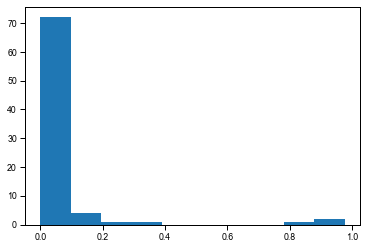

In [99]:
plt.hist(q_vals)

In [100]:
def convert_q_val_to_starts(q_val):
    result = ''
    if q_val < 0.2:
        result += '*'
    if q_val < 0.05:
        result += '*'
    if q_val < 0.01:
        result += '*'
    return result

In [101]:
set(top_genes) & set(may_genes), set(top_genes) & set(zeng_genes)

({'CARTPT'}, {'CARTPT', 'CCK', 'CXCL14'})

In [102]:
set(bottom_genes) & set(may_genes), set(bottom_genes) & set(zeng_genes)

(set(), set())

In [103]:
top_genes + bottom_genes

['MT-CO1',
 'HOPX',
 'MTRNR2L1',
 'ENC1',
 'MT-ND4',
 'HPCAL1',
 'CCK',
 'CXCL14',
 'CARTPT',
 'SLC1A2',
 'SAA1',
 'PCDH8',
 'SERPINE2',
 'NDUFA4',
 'OLFM1',
 'LAMP5',
 'MALAT1',
 'CALB2',
 'FABP4',
 'CKB',
 'QDPR',
 'OPALIN',
 'CRYAB',
 'CARNS1',
 'MOG',
 'TUBA1A',
 'PPP1R14A',
 'BCAS1',
 'CLDN11',
 'SEPT4',
 'SCGB2A2',
 'ERMN',
 'SPP1',
 'MAG',
 'CLDND1',
 'CNP',
 'TF',
 'MOBP',
 'PLP1',
 'MBP']

In [104]:
result_q_val_starts = pandas.DataFrame([
    [convert_q_val_to_starts(x)]
    for x in q_vals],
    index=zang_and_may,
)

In [105]:
result_q_val_starts.values[:, 0]

array(['***', '*', '***', '***', '***', '***', '***', '***', '', '***',
       '*', '***', '', '***', '***', '***', '***', '***', '***', '',
       '***', '***', '***', '***', '*', '***', '***', '***', '*', '*',
       '***', '***', '', '***', '***', '***', '***', '***', '***', '***',
       '***', '***', '***', '**', '***', '***', '***', '***', '***', '**',
       '***', '***', '***', '***', '***', '***', '***', '***', '***',
       '***', '***', '***', '', '***', '***', '*', '***', '***', '***',
       '***', '***', '***', '***', '***', '***', '*', '***', '***', '***',
       '***', '***'], dtype=object)

In [106]:
len(result_q_val_starts)

81

In [107]:
correlations_df = pandas.DataFrame(
    correlations,
    index=zang_and_may,
    columns=['Diffusion\nDim 0'],
)
correlations_df.index.name = 'Genes'


In [118]:
correlations_d_df = pandas.DataFrame(
    correlations_d,
    index=zang_and_may,
    columns=['PLD.0', 'PLD.1'],
)
correlations_d_df.index.name = 'Genes'


In [108]:
may_zeng_layers_colors.columns = [
    f'Layer {i}'
    for i in range(1, 6 + 1)
]

In [109]:
may_zeng_layers_colors

,Layer 1,Layer 2,Layer 3,Layer 4,Layer 5,Layer 6
GABRA5,"(0.9, 0.9, 0.9)","(0.9, 0.9, 0.9)","(0.9, 0.9, 0.9)","(0.9, 0.9, 0.9)","(0, 0, 0)","(0, 0, 0)"
SV2C,"(0.9, 0.9, 0.9)","(0.9, 0.9, 0.9)","(0, 0, 0)","(0.9, 0.9, 0.9)","(0.9, 0.9, 0.9)","(0.9, 0.9, 0.9)"
LGALS1,"(0.9, 0.9, 0.9)","(0.9, 0.9, 0.9)","(0, 0, 0)","(0.9, 0.9, 0.9)","(0, 0, 0)","(0, 0, 0)"
SCN3B,"(0.9, 0.9, 0.9)","(0, 0, 0)","(0, 0, 0)","(0.9, 0.9, 0.9)","(0.9, 0.9, 0.9)","(0, 0, 0)"
PENK,"(0.9, 0.9, 0.9)","(0, 0, 0)","(0, 0, 0)","(0.9, 0.9, 0.9)","(0.9, 0.9, 0.9)","(0, 0, 0)"
...,...,...,...,...,...,...
TBR1,"(0.9, 0.9, 0.9)","(0, 0, 0)","(0, 0, 0)","(0.9, 0.9, 0.9)","(0, 0, 0)","(0, 0, 0)"
LMO4,"(0.9, 0.9, 0.9)","(0, 0, 0)","(0, 0, 0)","(0, 0, 0)","(0, 0, 0)","(0, 0, 0)"
CXCL14,"(0, 0, 0)","(0, 0, 0)","(0.9, 0.9, 0.9)","(0.9, 0.9, 0.9)","(0.9, 0.9, 0.9)","(0.9, 0.9, 0.9)"
SATB2,"(0.9, 0.9, 0.9)","(0, 0, 0)","(0, 0, 0)","(0.9, 0.9, 0.9)","(0.9, 0.9, 0.9)","(0.9, 0.9, 0.9)"


/tmp/ipykernel_3696825/3520683133.py:29: UserWarning: FixedFormatter should only be used together with FixedLocator
  _ = may_cm.ax_cbar.set_yticklabels(may_cm.ax_cbar.get_yticklabels(), size=6)


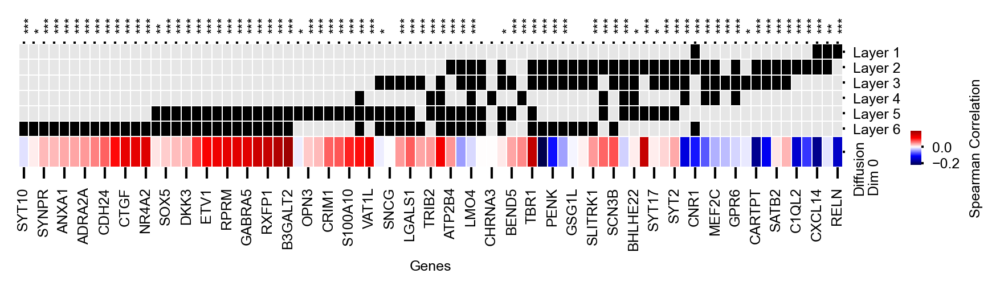

In [110]:
may_cm = sns.clustermap(
    correlations_df.iloc[(-2 * avg_layer + correlations_df.values[:, 0]).argsort(), :].T, 
    col_colors=may_zeng_layers_colors, 
    row_cluster=False,
    col_cluster=False,
    #annot=result_q_val_starts.iloc[(-2 * avg_layer + correlations_df.values[:, 0]).argsort(), :].T,
    fmt='',
    annot_kws={'rotation': 90, 'ha': 'left', 'va': 'center'},
    center=0, 
    #yticklabels=numpy.array(may_genes)[correlations_df.loc[may_genes][0].argsort()],
    cmap='seismic',
    cbar_pos=(1., 0.1, 0.01, 0.2),
    colors_ratio=0.1,
    linewidth=0.01,
    cbar_kws={'label': 'Spearman Correlation'},
)

may_cm.fig.set_dpi(300)
may_cm.fig.set_size_inches((6.5, 1))

_ = may_cm.ax_heatmap.set_yticklabels(may_cm.ax_heatmap.get_yticklabels(), size=6)
_ = may_cm.ax_heatmap.set_xticklabels(may_cm.ax_heatmap.get_xticklabels(), size=6)

_ = may_cm.ax_col_colors.set_yticklabels(may_cm.ax_col_colors.get_yticklabels(), size=6)
_ = may_cm.ax_col_colors.yaxis.set_tick_params(size=1)
_ = may_cm.ax_heatmap.yaxis.set_tick_params(size=1)
_ = may_cm.ax_col_dendrogram.set_visible(False)
_ = may_cm.ax_row_dendrogram.set_visible(False)
_ = may_cm.ax_cbar.set_yticklabels(may_cm.ax_cbar.get_yticklabels(), size=6)
_ = may_cm.ax_cbar.yaxis.set_tick_params(size=1)


stars = list(result_q_val_starts.iloc[(-2 * avg_layer + correlations_df.values[:, 0]).argsort(), 0].T.values)

_ = may_cm.ax_col_colors.xaxis.set_tick_params(
    top=True, bottom=False, size=1, direction='out', labeltop=True, labelbottom=False)
_ = may_cm.ax_col_colors.set_xticks(
    [i + 0.5 for i in range(len(stars))],
    labels=stars,
    size=6,
)

_ = may_cm.ax_col_colors.set_xticklabels(
    labels=stars,
    size=6,
    rotation=90,
    va='bottom',
    ha='left',
)


In [111]:
result_q_val_starts.iloc[(-2 * avg_layer + correlations_df.values[:, 0]).argsort(), 0].T.values

array(['***', '*', '***', '***', '***', '***', '***', '***', '***', '***',
       '***', '***', '***', '**', '***', '***', '***', '***', '***',
       '***', '***', '***', '***', '***', '***', '***', '***', '*', '***',
       '***', '***', '***', '***', '***', '***', '*', '', '***', '***',
       '***', '***', '***', '***', '***', '***', '', '', '*', '***',
       '***', '***', '***', '***', '***', '', '', '***', '***', '***',
       '***', '*', '***', '*', '***', '***', '***', '***', '***', '***',
       '***', '***', '*', '***', '***', '***', '***', '***', '***', '***',
       '**', '***'], dtype=object)

/tmp/ipykernel_3696825/3842569079.py:26: UserWarning: FixedFormatter should only be used together with FixedLocator
  _ = may_cm.ax_cbar.set_yticklabels(may_cm.ax_cbar.get_yticklabels(), size=6)


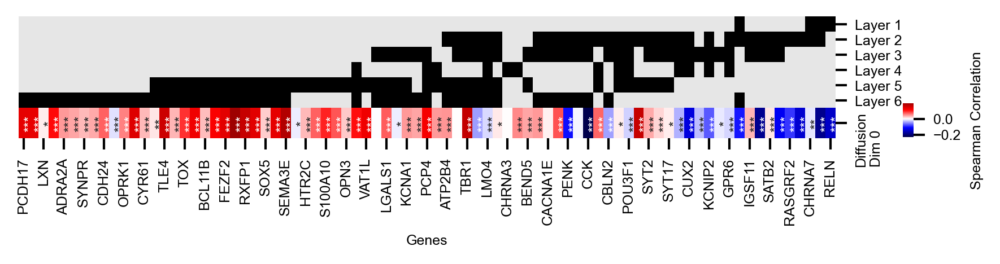

In [112]:
may_cm = sns.clustermap(
    correlations_df.iloc[(-2 * avg_layer).argsort(), :].T, 
    col_colors=may_zeng_layers_colors, 
    row_cluster=False,
    col_cluster=False,
    annot=result_q_val_starts.iloc[(-2 * avg_layer).argsort(), :].T,
    fmt='',
    annot_kws={'rotation': 90, 'ha': 'left', 'va': 'center'},
    center=0, 
    #yticklabels=numpy.array(may_genes)[correlations_df.loc[may_genes][0].argsort()],
    cmap='seismic',
    cbar_pos=(1., 0.1, 0.01, 0.2),
    colors_ratio=0.1,
    cbar_kws={'label': 'Spearman Correlation'},
)

may_cm.fig.set_dpi(300)
may_cm.fig.set_size_inches((6.5, 1))

_ = may_cm.ax_heatmap.set_yticklabels(may_cm.ax_heatmap.get_yticklabels(), size=6)
_ = may_cm.ax_heatmap.set_xticklabels(may_cm.ax_heatmap.get_xticklabels(), size=6)

_ = may_cm.ax_col_colors.set_yticklabels(may_cm.ax_col_colors.get_yticklabels(), size=6)
_ = may_cm.ax_col_dendrogram.set_visible(False)
_ = may_cm.ax_row_dendrogram.set_visible(False)
_ = may_cm.ax_cbar.set_yticklabels(may_cm.ax_cbar.get_yticklabels(), size=6)

In [113]:
avg_layer

array([4.5       , 2.        , 3.66666667, 2.66666667, 2.66666667,
       5.        , 2.        , 3.33333333, 3.66666667, 2.5       ,
       4.        , 4.        , 2.66666667, 4.5       , 4.        ,
       4.5       , 1.5       , 2.        , 1.5       , 2.66666667,
       4.        , 4.5       , 2.33333333, 0.        , 3.        ,
       4.5       , 3.5       , 5.        , 3.66666667, 5.        ,
       5.        , 4.        , 3.        , 5.        , 3.66666667,
       5.        , 5.        , 2.        , 3.5       , 3.        ,
       5.        , 2.33333333, 2.        , 0.5       , 3.        ,
       2.        , 1.        , 2.        , 2.66666667, 4.5       ,
       2.5       , 5.        , 5.        , 3.        , 3.5       ,
       2.66666667, 1.5       , 4.        , 2.66666667, 4.        ,
       4.        , 4.5       , 3.        , 4.5       , 4.5       ,
       2.5       , 5.        , 5.        , 4.5       , 4.5       ,
       1.        , 4.5       , 4.5       , 4.5       , 5.     

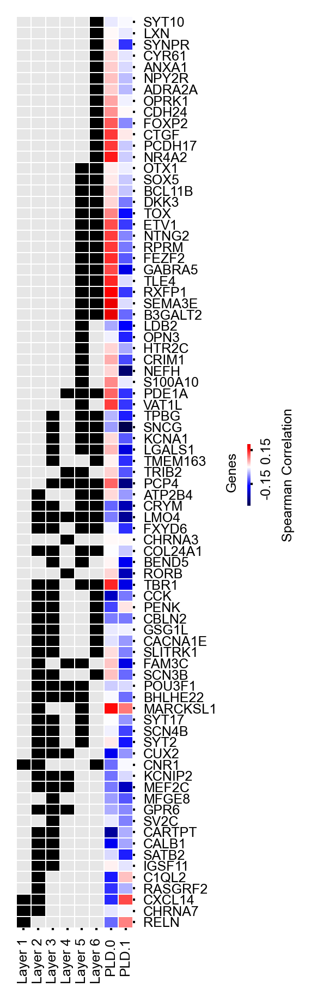

In [162]:
may_cm = sns.clustermap(
    correlations_d_df.iloc[(-2 * avg_layer + correlations_df.values[:, 0]).argsort(), :], 
    row_colors=may_zeng_layers_colors, 
    row_cluster=False,
    col_cluster=False,
    yticklabels=1,
    #annot=result_q_val_starts.iloc[(-2 * avg_layer + correlations_df.values[:, 0]).argsort(), :].T,
    fmt='',
    #annot_kws={'rotation': 90, 'ha': 'left', 'va': 'center'},
    center=0, 
    #yticklabels=numpy.array(may_genes)[correlations_df.loc[may_genes][0].argsort()],
    cmap='seismic',
    cbar_pos=(1.6, 0.405, 0.02, 0.05),
    colors_ratio=0.1,
    linewidth=0.01,
    cbar_kws={'label': 'Spearman Correlation'},
)

may_cm.fig.set_dpi(300)
may_cm.fig.set_size_inches((1, 7.5))

_ = may_cm.ax_heatmap.set_yticklabels(may_cm.ax_heatmap.get_yticklabels(), size=6, rotation=0)
_ = may_cm.ax_heatmap.set_xticklabels(may_cm.ax_heatmap.get_xticklabels(), size=6, rotation=90)

_ = may_cm.ax_row_colors.set_xticklabels(may_cm.ax_row_colors.get_xticklabels(), size=6)
_ = may_cm.ax_row_colors.xaxis.set_tick_params(size=1)
_ = may_cm.ax_heatmap.yaxis.set_tick_params(size=1)
_ = may_cm.ax_heatmap.xaxis.set_tick_params(size=1)
_ = may_cm.ax_col_dendrogram.set_visible(False)
_ = may_cm.ax_row_dendrogram.set_visible(False)
_ = may_cm.ax_cbar.set_yticks(
    [-.15, .15],
    [-.15, .15], 
    size=6, va='center')
_ = may_cm.ax_cbar.yaxis.set_tick_params(size=1, rotation=90)


# stars = list(result_q_val_starts.iloc[(-2 * avg_layer + correlations_df.values[:, 0]).argsort(), 0].T.values)

# _ = may_cm.ax_col_colors.xaxis.set_tick_params(
#     top=True, bottom=False, size=1, direction='out', labeltop=True, labelbottom=False)
# _ = may_cm.ax_col_colors.set_xticks(
#     [i + 0.5 for i in range(len(stars))],
#     labels=stars,
#     size=6,
# )

# _ = may_cm.ax_col_colors.set_xticklabels(
#     labels=stars,
#     size=6,
#     rotation=90,
#     va='bottom',
#     ha='left',
# )


In [117]:
mean_markers = bag_cello_df.cell_df.groupby('cellohood_neighborhood_cluster')[MARKER_COL_NAMES].mean()
max_markers = bag_cello_df.cell_df.groupby('cellohood_neighborhood_cluster')[MARKER_COL_NAMES].max()
min_markers = bag_cello_df.cell_df.groupby('cellohood_neighborhood_cluster')[MARKER_COL_NAMES].min()

In [118]:
mm_ccs = bag_cello_df.cell_df.groupby('cellohood_neighborhood_cluster')['cellohood_neighborhood_cluster'].first()

In [119]:
agg_markers = pandas.concat([mean_markers, max_markers, min_markers], axis=1)

In [120]:
mean_marker_samples = bag_cello_df.cell_df.groupby('cellohood_neighborhood_cluster')['sample'].first()

  0%|                                                                                                                                                                                | 0/10 [00:00<?, ?it/s]

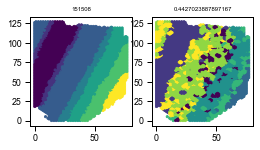

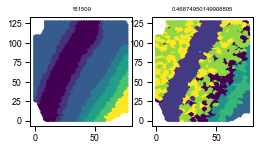

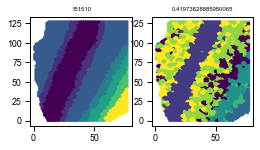

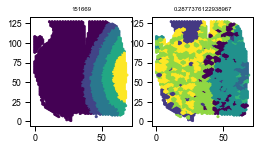

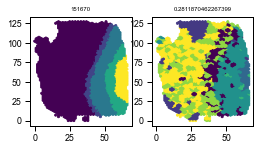

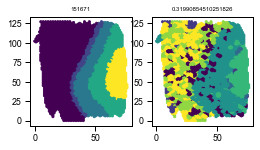

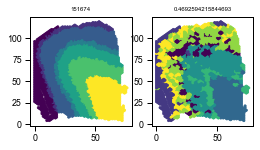

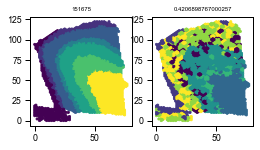

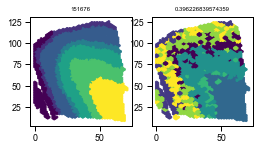

 10%|████████████████▊                                                                                                                                                       | 1/10 [00:05<00:47,  5.24s/it]

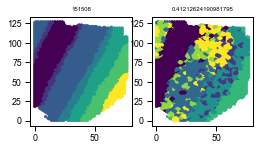

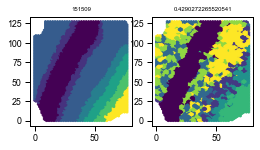

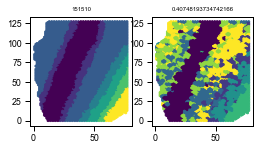

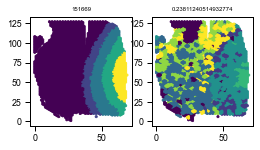

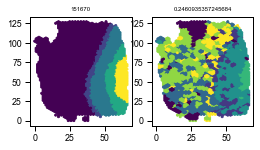

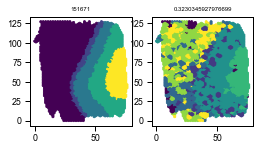

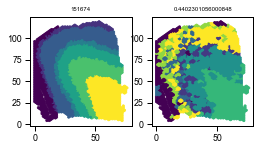

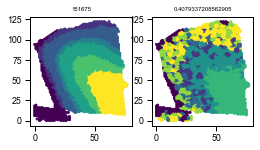

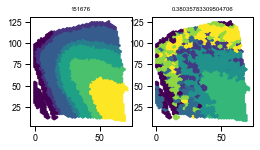

 20%|█████████████████████████████████▌                                                                                                                                      | 2/10 [00:09<00:39,  4.92s/it]

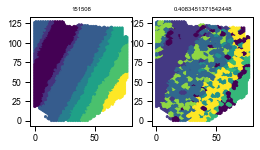

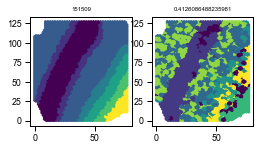

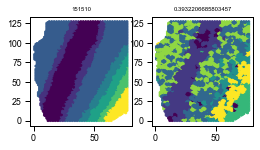

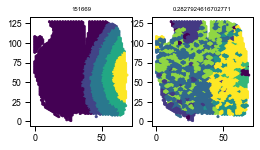

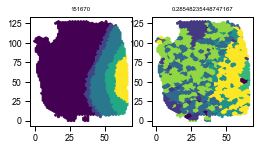

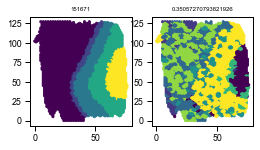

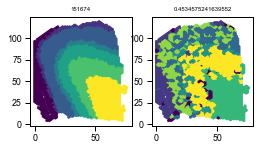

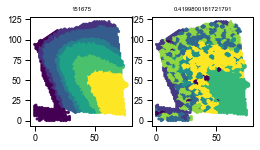

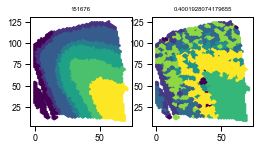

 30%|██████████████████████████████████████████████████▍                                                                                                                     | 3/10 [00:15<00:35,  5.05s/it]

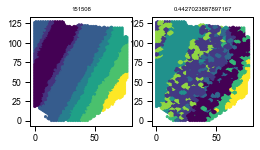

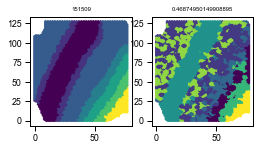

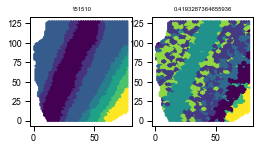

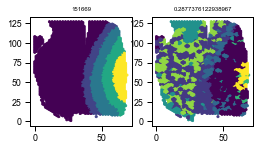

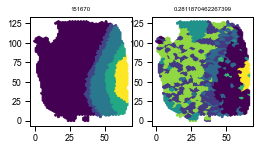

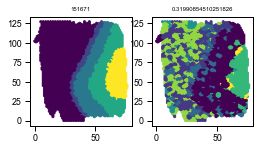

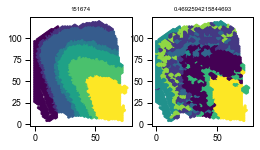

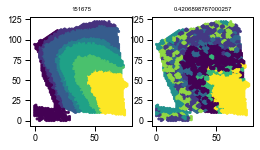

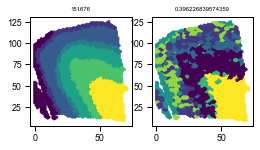

 40%|███████████████████████████████████████████████████████████████████▏                                                                                                    | 4/10 [00:20<00:30,  5.15s/it]

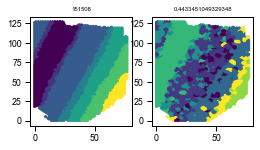

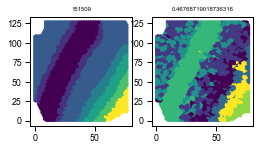

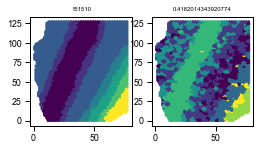

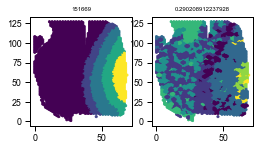

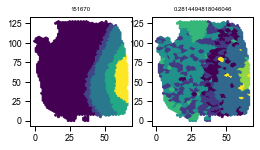

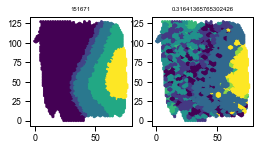

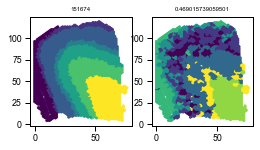

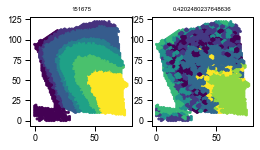

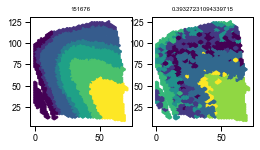

 50%|████████████████████████████████████████████████████████████████████████████████████                                                                                    | 5/10 [00:25<00:26,  5.24s/it]

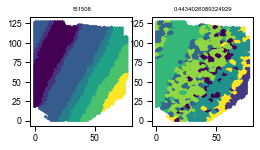

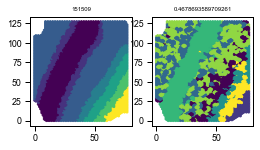

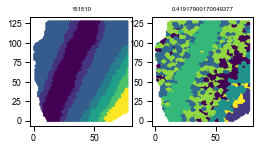

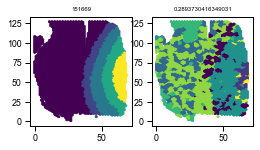

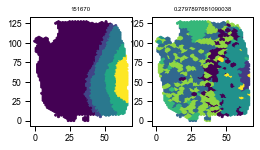

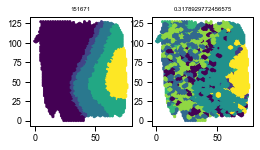

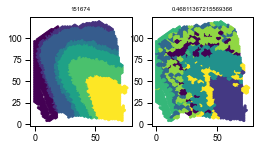

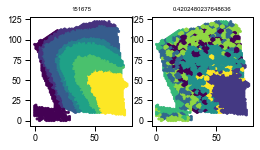

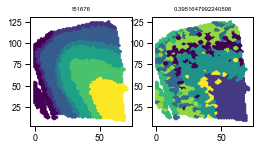

 60%|████████████████████████████████████████████████████████████████████████████████████████████████████▊                                                                   | 6/10 [00:30<00:20,  5.17s/it]

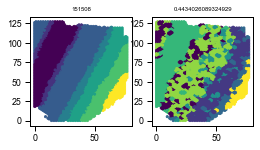

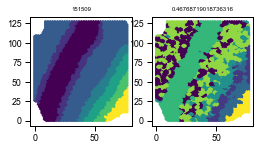

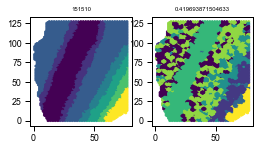

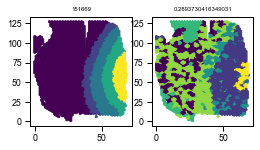

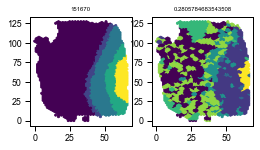

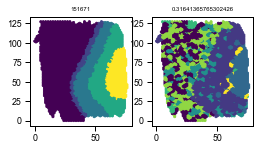

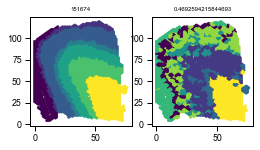

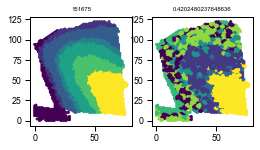

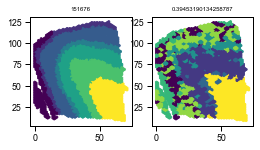

 70%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▌                                                  | 7/10 [00:36<00:15,  5.17s/it]

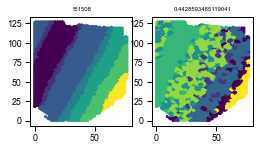

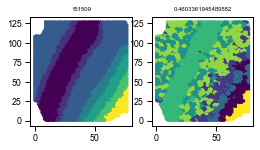

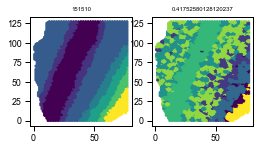

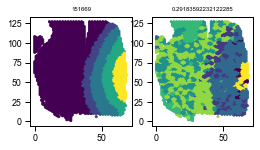

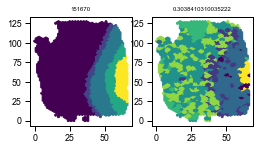

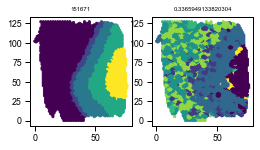

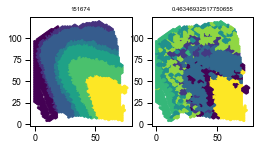

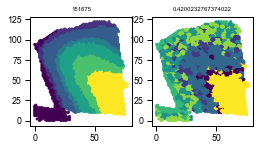

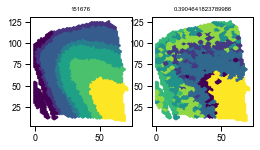

 80%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▍                                 | 8/10 [00:41<00:10,  5.17s/it]

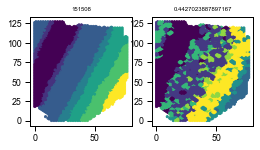

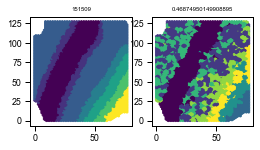

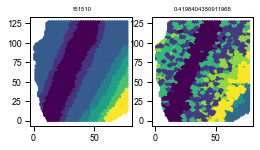

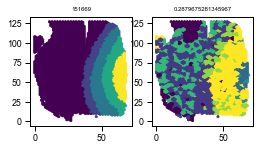

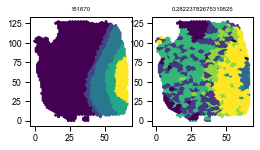

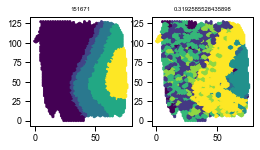

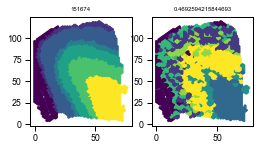

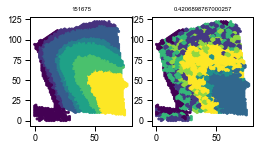

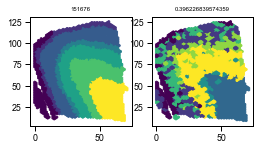

 90%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▏                | 9/10 [00:47<00:05,  5.51s/it]

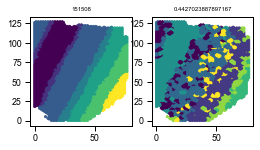

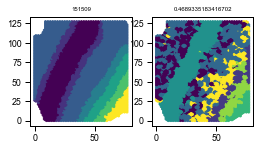

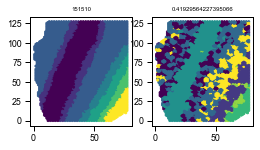

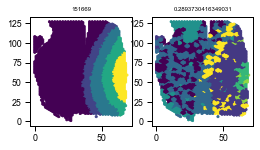

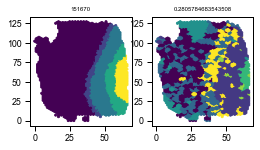

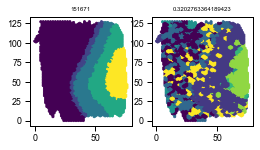

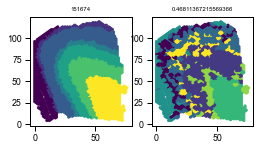

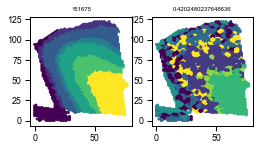

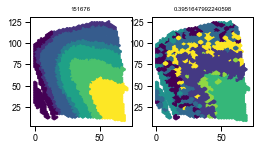

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 10/10 [00:52<00:00,  5.25s/it]


In [121]:
NB_OF_RUNS = 10


# From Cellcharter paper
TEST_SAMPLES = [
    151507,
    151672,
    151673
]

NON_TEST_SAMPLES = [
    sample 
    for sample in sorted(bag_cello_df.cell_df['sample'].unique())
    if sample not in TEST_SAMPLES
]


current_random_seed = 42
sample_to_aris = defaultdict(list)
clusterers = []
variables = [0, 1]

train_cello_m_df = agg_markers[mean_marker_samples.apply(lambda x: x not in TEST_SAMPLES)]
mm_ccs_train = mm_ccs[mean_marker_samples.apply(lambda x: x not in TEST_SAMPLES)]


for _ in tqdm.tqdm(range(NB_OF_RUNS)):
    # Fitting the model
    current_clusterer = GaussianMixture(7, random_state=current_random_seed)
    current_random_seed += 1
    training_ld = train_cello_m_df# / decomposer.explained_variance_ratio_[:2]
    predictions = current_clusterer.fit_predict(training_ld)
    cc_to_pred = {cc: pred for cc, pred in zip(mm_ccs_train, predictions)}
    clusterers.append(current_clusterer)
    
    # Running prediction on samples
    for sample in sorted(bag_cello_df.cell_df['sample'].unique()):
        if sample in TEST_SAMPLES:
            continue
        sample_all_df = bag_cello_df.cell_df[bag_cello_df.cell_df['sample'] == sample]
        sample_non_unk_df = sample_all_df[sample_all_df['layer'] != 'UNK']
        sample_gt = sample_non_unk_df['layer'].apply(lambda x: layers_.index(x))
        
        
        sample_preds = sample_non_unk_df['cellohood_neighborhood_cluster'].apply(lambda x: cc_to_pred[x])
        current_ari = adjusted_rand_score(sample_preds, sample_gt)
        
        sample_to_aris[sample].append(current_ari)
        
        plt.figure(figsize=(4, 2))
        plt.subplot(1, 2, 1)
        plt.scatter(
            sample_non_unk_df.pos_x,
            sample_non_unk_df.pos_y,
            c=sample_non_unk_df['layer'].apply(lambda x: layers_.index(x)),
            s=5,
        )
        plt.title(sample)
        plt.subplot(1, 2, 2)
        plt.scatter(
            sample_non_unk_df.pos_x,
            sample_non_unk_df.pos_y,
            c=sample_preds,
            s=5,
        )
        plt.title(current_ari)
        plt.show()

In [122]:
train_means_mm = []
for sample_id, sample in enumerate(sorted(sample_to_aris)):
    train_means_mm.append(numpy.mean(sample_to_aris[sample]))

In [123]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, ConnectionPatch
import seaborn as sns
from scipy import stats

def compute_pvalues(data_lists, reference_idx):
    """
    Compute p-values comparing reference method to all others using two-sided t-test
    
    Parameters:
    -----------
    data_lists : list of lists
        Each inner list contains the scores for one method
    reference_idx : int
        Index of the reference method
        
    Returns:
    --------
    list of float
        P-values for each comparison (None for reference method)
    """
    pvalues = []
    reference_data = data_lists[reference_idx]
    
    for i, data in enumerate(data_lists):
        if i == reference_idx:
            pvalues.append(None)
        else:
            # Perform two-sided t-test
            print(len(data), len(reference_data))
            _, pval = stats.ttest_rel(reference_data, data)
            pvalues.append(pval)
            
    return pvalues

def plot_boxplot_with_stats_2(data_lists, method_names, my_method_idx, 
                           figsize=(3, 2), my_method_color='lightblue',
                           other_methods_color='lightgray', sig_threshold=0.05):
    """
    Create a boxplot with significance bars connecting to a reference method.
    
    Parameters:
    -----------
    data_lists : list of lists
        Each inner list contains the scores for one method
    method_names : list of str
        Names of the methods
    my_method_idx : int
        Index of your method in the lists
    figsize : tuple
        Figure size
    my_method_color : str
        Color for your method's box
    other_methods_color : str
        Color for other methods' boxes
    sig_threshold : float
        Significance threshold for p-values
    """
    
    # Compute p-values
    pvalues = compute_pvalues(data_lists, my_method_idx)
    print(pvalues)
    
    # Create figure and axis
    fig, ax = plt.subplots(figsize=figsize, dpi=300)
    
    # Create colors list
    colors = [other_methods_color] * len(method_names)
    colors[my_method_idx] = my_method_color
    
    # Create boxplot
    box_ratio = 1.25
    bplot = ax.boxplot(data_lists, patch_artist=True, positions=box_ratio * numpy.arange(len(colors)))
    
    # Color the boxes
    for patch, color in zip(bplot['boxes'], colors):
        patch.set_facecolor(color)
    
    # Set the labels
    ax.set_xticklabels(method_names, rotation=30, ha='right', size=6)
    
    # Get the positions of boxes for connecting lines
    my_method_pos = my_method_idx + 1  # boxplot positions start at 1
    
    # Get the maximum value in the data for scaling
    max_val = max([max(sublist) for sublist in data_lists])
    min_val = min([min(sublist) for sublist in data_lists])
    print(max_val, min_val)
    plot_range = max_val - min_val
    
    # Space between bars
    step = plot_range * 0.1
    
    # Draw connecting lines and p-values
    for i, (pval, data) in enumerate(zip(pvalues, data_lists)):
        if i != my_method_idx:
            # Calculate height for this comparison
            curr_pos = i + 1  # boxplot positions start at 1
            height = max_val - 0.1 + step * (0.1 + abs(curr_pos)) * 1.5
            
            # Draw the line
            x1, x2 = sorted([my_method_pos, curr_pos])
            x1 = x1 * box_ratio - box_ratio
            x2 = x2 * box_ratio - box_ratio
            line = plt.hlines(y=height, xmin=x1, xmax=x2, color='black', linestyle='-', linewidth=0.6)
            
            # Add vertical line
            plt.vlines(x=x1, ymin=height - 0.01, ymax=height, color='black', linestyle='-', linewidth=0.6)
            plt.vlines(x=x2, ymin=height - 0.01, ymax=height, color='black', linestyle='-', linewidth=0.6)
            
            # Add p-value annotation
            text_pos = (x1 + x2) / 2
            
            # Format p-value
            if pval < 0.001:
                pval_text = 'p < 0.001'
            else:
                pval_text = f'p = {pval:.3f}'
            
            # Add asterisks for significance
            if pval < sig_threshold:
                asterisks = '*' * sum([pval < thresh for thresh in [0.05, 0.01, 0.001]])
                pval_text = f'{pval_text} ({asterisks})'
            
            plt.text(text_pos, height + step*0.1, pval_text, size=6,
                    horizontalalignment='center', verticalalignment='bottom')
    
    plt.plot([-0.5, 9.], [numpy.median(train_means)] * 2, '--', c='orange', linewidth=0.5)
    plt.text(
        3.25, 
        numpy.median(train_means) + 0.01, 
        f'Cellohood Median Score (ARI={round(numpy.median(train_means), 2)})', size=6, style='italic')
    
    # Adjust the plot limits to show all bars
    #plt.ylim(min_val - 0.05, max_val + 0.05)
    #plt.axes(frameon=False)
    
    # Add labels and title
    plt.ylabel('ARI', size=6, labelpad=1)
    plt.xlabel('Method', size=6, labelpad=1)
    ax.set_yticklabels(ax.get_yticklabels(), size=6)
    ax.set_xticklabels(ax.get_xticklabels(), size=6)
    ax.spines[['right', 'top']].set_visible(False)
    #ax.set_aspect(6)
    ax.yaxis.set_tick_params(size=1, pad=1)
    ax.xaxis.set_tick_params(size=1, pad=1)
    #ax.set_ylim([0, 1.])
    
    # Adjust layout to prevent label cutoff
    #plt.tight_layout()
    
    return fig, ax, pvalues



9 9
9 9
9 9
9 9
9 9
9 9
9 9
[None, 0.0020561530299759447, 0.00015208818340437986, 5.522645428498212e-06, 2.5374583713468347e-07, 0.0011215362836663788, 2.70749012859218e-07, 1.1911288261519032e-06]
0.6248244629405463 0.19912727410983128


/tmp/ipykernel_1276659/1270772060.py:142: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_yticklabels(ax.get_yticklabels(), size=6)


(<Figure size 900x600 with 1 Axes>,
 <Axes: xlabel='Method', ylabel='ARI'>,
 [None,
  0.0020561530299759447,
  0.00015208818340437986,
  5.522645428498212e-06,
  2.5374583713468347e-07,
  0.0011215362836663788,
  2.70749012859218e-07,
  1.1911288261519032e-06])

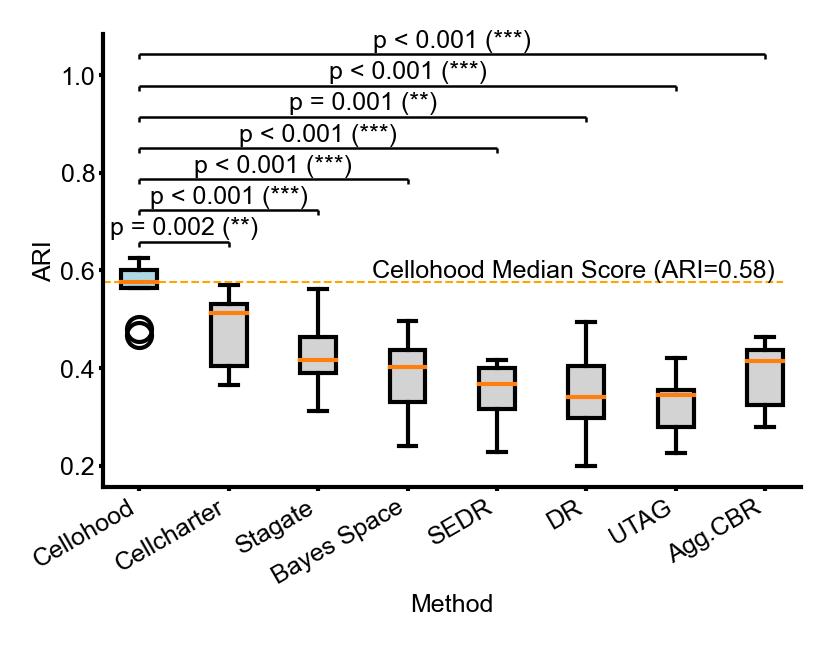

In [124]:
plot_boxplot_with_stats_2(
    ([train_means_mm] + list(method_to_results_means.values()) + [train_means])[::-1],
    (['Agg.CBR'] + list(method_to_results_means.keys()) + ['Cellohood'])[::-1],
    0, #len(list(method_to_results_means.values()) + [train_means]),
)